# Predicción de precios de casas en Quito y los valles

**Proyecto final – Aprendizaje Supervisado (USFQ, 202610)**

**Autor:** Marcelo Atiaga

**Asistencia de IA:** Claude Opus 5.5 (Anthropic); ver la sección 14

**Repositorio:** https://github.com/marcejose-ec/usfq-supervisado-proyecto-final

---

**Contenido**
1. Introducción
2. Configuración
3. Carga de datos
4. Análisis exploratorio de datos (EDA)
5. Preparación para el modelado
6. Partición entrenamiento / prueba
7. Pipeline: preprocesamiento, selección de características y modelo
8. Optimización de hiperparámetros (Optuna + repeated k-fold CV)
9. Curvas de validación y de aprendizaje
10. Comparación estadística de dos técnicas
11. Evaluación final en el conjunto de prueba
12. Visualización del espacio de características con t-SNE
13. Conclusiones
14. Transparencia sobre el uso de IA
15. Referencias

## 1. Introducción

La vivienda es, para la mayoría de los hogares ecuatorianos, la inversión más grande de su vida. Sin embargo, en Quito
no existe un índice público y actualizado de precios de vivienda a nivel de barrio: compradores, vendedores y
agentes inmobiliarios fijan precios principalmente por comparación informal con anuncios cercanos. Esto genera
asimetrías de información, sobreprecios y dificulta la toma de decisiones tanto de familias como de entidades
financieras que otorgan créditos hipotecarios.

El Distrito Metropolitano de Quito presenta además una particularidad geográfica: junto a la ciudad consolidada
(norte, centro y sur) han crecido los **valles** (Cumbayá, Tumbaco, Valle de los Chillos, entre otros), con
dinámicas de precio muy distintas: lotes más grandes, predominio de casas sobre departamentos y una fuerte
valorización en la última década. Un modelo que capture estas diferencias es útil para:

- **Compradores y vendedores:** obtener un precio de referencia objetivo antes de negociar.
- **Bancos y aseguradoras:** apoyar avalúos y detectar anuncios atípicos.
- **Planificación urbana:** entender qué características (ubicación, área, amenidades) explican el valor del suelo.

**Objetivo:** construir un modelo de regresión supervisada que prediga el precio de venta (USD) de una vivienda en
Quito y sus valles a partir de sus características (área, habitaciones, baños, parqueaderos, ubicación, etc.),
siguiendo una metodología rigurosa: pipelines de `scikit-learn`, selección de características tipo filtro,
optimización de hiperparámetros con *repeated k-fold cross-validation* y una comparación estadística formal entre
dos técnicas de aprendizaje automático.

En los 7.151 anuncios de venta recolectados para este proyecto (noviembre de 2026) [10], el precio mediano es de
USD 149.000 y el precio mediano por m² va de ≈ USD 590 (casas en Pomasqui–Calderón) a ≈ USD 1.650 (departamentos en
Cumbayá–Tumbaco): una diferencia de casi tres veces dentro del mismo distrito.

> **Aviso sobre el alcance de los datos.** En este ejercicio el dataset se trata como si fuera una visión completa
> del mercado, y no lo es. El portal inmobiliario más grande del país (plusvalia.com) no se pudo recolectar, y la
> mayor parte del mercado de vivienda de Quito no se publica en internet: se negocia directamente, por referidos o a
> través de corredores. RE/MAX cubre una parte importante del mercado que no es solo en línea, pero no lo representa
> completo. El dataset es, por tanto, un **subconjunto no aleatorio** del mercado: anuncios en línea, con precios de
> oferta (no de cierre), recolectados en noviembre de 2026. Esto es aceptable para un ejercicio de metodología de
> aprendizaje automático como este notebook, pero **los modelos entrenados aquí no están pensados como un predictor
> práctico del precio de la vivienda en Quito.**
>
> Quito agrava este sesgo: en el norte, las zonas más ricas suelen estar junto a las más pobres. El Bosque colinda
> con La Comuna; Campo Alegre (en Monteserrín) y Lomas de Monteserrín, con Buenos Aires y Zámbiza; y en Nayón, que no
> forma parte de Quito urbano, hay casas comunitarias pequeñas junto a mansiones. En el dataset El Bosque tiene 83
> anuncios, Monteserrín 56 y Lomas de Monteserrín 23, mientras que La Comuna, Buenos Aires y Zámbiza no tienen
> ninguno; y en Nayón la dispersión del precio por m² es incluso menor que la de un sector típico. Es decir, los
> vecindarios más pobres prácticamente no aparecen en los anuncios en línea. Como el modelo supone que el precio varía
> de forma suave en el espacio (sectores vecinos con precios parecidos, sección 4.8), una vivienda en esos vecindarios
> recibiría un precio extrapolado de sus vecinos ricos y quedaría muy sobrevaluada.

## 2. Configuración

`MODO_RAPIDO = True` reduce repeticiones y número de *trials* para probar el notebook de principio a fin en pocos
minutos. **Para los resultados finales usar `MODO_RAPIDO = False`.**

In [1]:
# Uso de herramientas de IA: el código de este notebook fue escrito con Claude Opus 5.5 (Anthropic).
# Qué hizo la IA y qué decidió el autor se detalla en la sección 14 (Transparencia sobre el uso de IA).

import warnings

# Sin ipywidgets (p. ej. al ejecutar con nbconvert), tqdm avisa al importarse; el aviso es inofensivo
warnings.filterwarnings("ignore", message="IProgress not found")

# En Colab, Optuna y PyTorch Lightning no vienen instalados por defecto (PyTorch sí)
try:
    import optuna
    import lightning
except ImportError:
    %pip install -q optuna lightning
    import optuna

In [2]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectPercentile, VarianceThreshold, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.manifold import TSNE
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import (RepeatedKFold, cross_val_score, learning_curve,
                                     train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ---------------- Parámetros globales ----------------
SEED = 42
MODO_RAPIDO = False

# Ruta local o URL "raw" de GitHub del dataset
DATA_PATH = "data/casas_quito.csv"
DATA_URL = "https://raw.githubusercontent.com/marcejose-ec/usfq-supervisado-proyecto-final/main/data/casas_quito.csv"

RESULTADOS = Path("resultados")        # tablas de resultados (CSV/JSON) que se suben al repositorio
RESULTADOS.mkdir(exist_ok=True)

TARGET = "precio"
SCORING = "neg_root_mean_squared_error"   # sobre y = log(precio) → RMSLE (sklearn lo maximiza en negativo)

if MODO_RAPIDO:
    CV_OPT = RepeatedKFold(n_splits=3, n_repeats=1, random_state=SEED)      # dentro de Optuna
    CV_COMP = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)     # comparación estadística
    N_TRIALS = 10
else:
    CV_OPT = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
    CV_COMP = RepeatedKFold(n_splits=10, n_repeats=10, random_state=SEED)
    N_TRIALS = 60

# Núcleos para paralelizar (-1 = todos). En un servidor compartido, fijar con la variable de entorno N_JOBS.
N_JOBS = int(os.environ.get("N_JOBS", -1))
rng = np.random.default_rng(SEED)
print("optuna", optuna.__version__, "| MODO_RAPIDO =", MODO_RAPIDO)

optuna 5.0.0 | MODO_RAPIDO = False


## 3. Carga de datos

7.151 anuncios de venta de casas y departamentos recolectados el 11–12 de noviembre de 2026 de icasas.ec, remax.com.ec, arriendayvende.com, trivo.com.ec y sitios de constructoras [10]. La fuente, el diccionario de variables y los pasos de limpieza previos están en `data/README.md`. Ver el aviso sobre el alcance de los datos al final de la introducción.

In [3]:
ruta = DATA_PATH if Path(DATA_PATH).exists() else DATA_URL
df_raw = pd.read_csv(ruta)

# Si el dataset trae año de construcción en vez de antigüedad, se convierte
print(f"Filas: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 7,151 | Columnas: 49


,id,fuente,url,fecha_publicacion,fecha_scraping,tipo,precio,area_construida_m2,habitaciones,banos,...,calefaccion,vista_panoramica,patio,jacuzzi_sauna,acceso_discapacitados,precio_m2,outlier_precio_m2,agencia,titulo,descripcion
0,arriendayvende_100050,arriendayvende.com,https://arriendayvende.com/propiedades/casa-en...,2022-07-06,2026-11-12,casa,75000.0,296.56,9.0,5.0,...,0.0,0.0,0.0,0.0,0.0,252.90,0,NaN,"CASA EN VENTA SECTOR LA ROLDOS, QUITO, ECUADOR",RONALD REGALADO #0998849892 ID: 890321322-38 D...
1,arriendayvende_100197,arriendayvende.com,https://arriendayvende.com/propiedades/casa-en...,2022-07-06,2026-11-12,casa,114500.0,160.00,3.0,2.0,...,0.0,0.0,1.0,0.0,0.0,715.62,0,NaN,"CASA EN VENTA BOCATOMA AV ILALO, QUITO, ECUADOR",NICOLE GRANJA #0997777847 ID: 890321310-98 Amp...
2,arriendayvende_100303,arriendayvende.com,https://arriendayvende.com/propiedades/casa-en...,2022-07-07,2026-11-12,casa,125000.0,123.00,3.0,3.0,...,0.0,0.0,1.0,1.0,0.0,1016.26,0,NaN,"CASA EN VENTA EN ALANGASÍ, QUITO, ECUADOR",JOHANNA FONTAL #0994288092 ID: 890321271-118 S...
3,arriendayvende_100362,arriendayvende.com,https://arriendayvende.com/propiedades/casa-en...,2022-07-07,2026-11-12,casa,230000.0,309.00,5.0,4.0,...,0.0,0.0,1.0,0.0,0.0,744.34,0,NaN,"CASA EN VENTA EN CONOCOTO, QUITO, ECUADOR",JOHANNA FONTAL #0994288092 ID: 890321271-119 E...
4,arriendayvende_100382,arriendayvende.com,https://arriendayvende.com/propiedades/casa-en...,2022-07-07,2026-11-12,casa,220000.0,429.00,11.0,6.0,...,0.0,0.0,0.0,0.0,0.0,512.82,0,NaN,"CASA EN VENTA EN SAN BARTOLO, QUITO, ECUADOR",GABRIEL RIVERA #0979418630 ID: 890321369-5 🔥𝐄𝐍...


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7151 entries, 0 to 7150
Data columns (total 49 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     7151 non-null   str    
 1   fuente                 7151 non-null   str    
 2   url                    7151 non-null   str    
 3   fecha_publicacion      1238 non-null   str    
 4   fecha_scraping         7151 non-null   str    
 5   tipo                   7151 non-null   str    
 6   precio                 7151 non-null   float64
 7   area_construida_m2     7151 non-null   float64
 8   habitaciones           7031 non-null   float64
 9   banos                  6656 non-null   float64
 10  canton                 7151 non-null   str    
 11  sector                 7143 non-null   str    
 12  sector_inferido        7151 non-null   int64  
 13  zona                   7150 non-null   str    
 14  es_valle               7150 non-null   float64
 15  latitud        

In [5]:
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,7151,6902,constructora_trivo.com.ec_beat_estudio,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuente,7151,9,icasas.ec,4261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
url,7151,6788,https://trivo.com.ec/propiedades/beat/,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_publicacion,1238,364,2022-10-20,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_scraping,7151,1,2026-11-12,7151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo,7151,2,casa,3863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precio,7151.0,NaN,NaN,NaN,205440.852828,211705.435124,15000.0,94700.0,149000.0,240000.0,5000000.0
area_construida_m2,7151.0,NaN,NaN,NaN,241.522156,218.549947,20.0,109.0,169.0,296.0,2000.0
habitaciones,7031.0,NaN,NaN,NaN,3.382307,2.032046,0.0,3.0,3.0,4.0,39.0
banos,6656.0,NaN,NaN,NaN,2.975361,5.176842,1.0,2.0,2.5,3.0,400.0


## 4. Análisis exploratorio de datos (EDA)

El EDA se hace **antes y fuera del pipeline de modelado**: es descriptivo y sirve para tomar decisiones informadas
sobre limpieza, transformación del objetivo, codificación de variables y filtrado de fuentes. Las transformaciones que
dependen de los datos (imputación, escalado, codificación, selección) se ajustan después **dentro** del pipeline,
solo con datos de entrenamiento.

### 4.1 Vista general

In [6]:
print(f"{len(df_raw):,} anuncios × {df_raw.shape[1]} columnas\n")
display(pd.crosstab(df_raw["fuente"], df_raw["tipo"], margins=True, margins_name="Total"))
display(pd.crosstab(df_raw["zona"].fillna("NA"), df_raw["tipo"], margins=True, margins_name="Total"))

7,151 anuncios × 49 columnas



tipo,casa,departamento,Total
fuente,,,
alvarezbravo.com.ec,0,1,1
arriendayvende.com,780,458,1238
barrazueta.com,1,0,1
casasventacumbaya.zenz.ec,3,0,3
corporacionvyasa.com,2,0,2
icasas.ec,2344,1917,4261
remax.com.ec,680,584,1264
ryp.com.ec,1,0,1
trivo.com.ec,52,328,380


tipo,casa,departamento,Total
zona,,,
NA,1,0,1
norte_pomasqui_calderon,496,75,571
quito_urbano,1298,2411,3709
rural_otro,6,0,6
valle_cumbaya_tumbaco,1065,630,1695
valle_los_chillos,997,172,1169
Total,3863,3288,7151


_Comentario:_ icasas.ec aporta el 60 % de los anuncios; las constructoras (fuera de Trivo) apenas 8 filas. Las casas
(3.863) y los departamentos (3.288) están equilibrados en total, pero no por zona: el 73 % de los departamentos está
en Quito urbano, mientras en los valles predominan las casas (en Los Chillos, 997 casas frente a 172 departamentos).
Por eso el tipo de vivienda y la zona se analizan juntos en todo el EDA. Las 7 filas de `rural_otro` o sin zona se
excluyen del modelado (sección 5).

### 4.2 Valores faltantes

En este dataset muchos faltantes son **estructurales** (la variable no aplica) y no aleatorios: por ejemplo, un
departamento no tiene área de terreno y una casa no tiene número de piso. Por eso se muestran por tipo de vivienda y
por fuente.

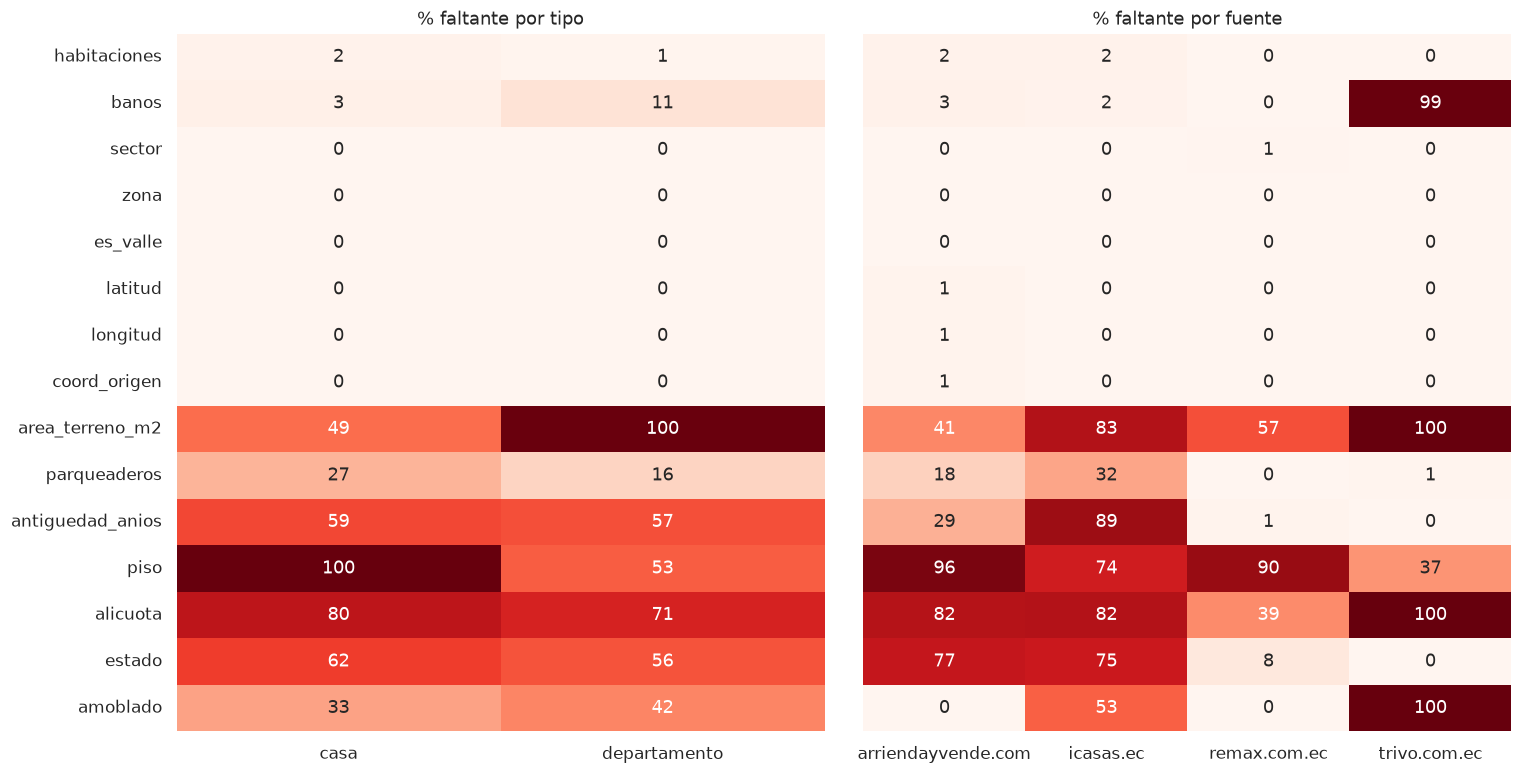

In [7]:
cols_falt = [c for c in df_raw.columns if df_raw[c].isna().any() and c not in ("fecha_publicacion", "agencia")]

fig, axes = plt.subplots(1, 2, figsize=(14, 0.38 * len(cols_falt) + 1.5), sharey=True)
sns.heatmap(df_raw.groupby("tipo")[cols_falt].apply(lambda g: g.isna().mean() * 100).T,
            annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar=False, ax=axes[0])
axes[0].set(title="% faltante por tipo", xlabel="", ylabel="")
fuentes_principales = ["icasas.ec", "remax.com.ec", "arriendayvende.com", "trivo.com.ec"]
sns.heatmap(df_raw[df_raw["fuente"].isin(fuentes_principales)].groupby("fuente")[cols_falt]
            .apply(lambda g: g.isna().mean() * 100).T,
            annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar=False, ax=axes[1])
axes[1].set(title="% faltante por fuente", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

_Comentario:_ los faltantes son sobre todo **estructurales** o dependen de la **fuente**: `area_terreno_m2` falta en el
100 % de los departamentos (no aplica) y en el 49 % de las casas; `piso` falta en el 100 % de las casas. icasas casi
nunca publica la antigüedad (89 % faltante), mientras RE/MAX casi siempre (1 %); Trivo no publica baños, alícuota ni
amoblado. Las coordenadas faltan en menos del 1 %. Los faltantes **no** se imputan aquí: la imputación (con indicador
de faltante) va dentro del pipeline, para que se aprenda solo con los datos de entrenamiento de cada fold.

### 4.3 Valores anómalos y casas renteras

Se revisan las colas de `habitaciones` y `banos`.

In [8]:
for c in ["habitaciones", "banos", "parqueaderos"]:
    print(f"{c:13s} cola:", df_raw[c].value_counts().sort_index().tail(10).to_dict())

cols_ver = ["fuente", "tipo", "habitaciones", "banos", "area_construida_m2", "precio", "titulo"]
df_raw[(df_raw["habitaciones"] > 10) | (df_raw["banos"] > 10)][cols_ver] \
    .sort_values("habitaciones", ascending=False).head(15)

habitaciones  cola: {16.0: 8, 17.0: 5, 18.0: 5, 19.0: 2, 20.0: 1, 21.0: 2, 24.0: 1, 25.0: 1, 36.0: 1, 39.0: 1}
banos         cola: {13.0: 3, 14.0: 1, 15.0: 5, 16.0: 1, 18.0: 1, 20.0: 1, 23.0: 1, 24.0: 3, 56.0: 1, 400.0: 1}
parqueaderos  cola: {1.0: 1896, 2.0: 2382, 3.0: 507, 4.0: 247, 5.0: 103, 6.0: 73, 7.0: 15, 8.0: 45, 9.0: 8, 10.0: 37}


,fuente,tipo,habitaciones,banos,area_construida_m2,precio,titulo
5532,icasas.ec,departamento,39.0,23.0,1735.00,800000.0,"Departamento en Av. Occidental, San Carlos, Q..."
3094,icasas.ec,departamento,36.0,2.0,242.00,175000.0,"Departamento en El Batán, Quito"
243,arriendayvende.com,casa,25.0,15.0,1162.76,300000.0,"CASA EN VENTA SECTOR SAN DIEGO, QUITO, ECUADOR"
758,arriendayvende.com,casa,24.0,24.0,1095.00,5000000.0,"Casa en venta sector La Mariscal, Quito, Ecuador"
1129,arriendayvende.com,departamento,21.0,1.0,60.00,60000.0,"Departamento en venta sector Universitario, Qu..."
1057,arriendayvende.com,departamento,21.0,1.0,56.00,37300.0,"Departamento en venta sector Villaflora, Quito..."
6835,remax.com.ec,casa,20.0,9.5,1217.04,240000.0,CASA RENTERA EN VENTA - SECTOR LA RECOLETA 1217m²
22,arriendayvende.com,casa,19.0,9.0,673.00,448000.0,"CASA DE VENTA EN EL TINGO ALANGASÍ, QUITO, ECU..."
309,arriendayvende.com,casa,19.0,9.0,1128.00,448000.0,"Casa de venta en el Tingo Alangasí, Quito, Ecu..."
4338,icasas.ec,casa,18.0,7.0,510.00,206999.0,"Casa en Avenida Andres Perez & V Castillo, Qu..."


La mayoría de viviendas con más de 10 habitaciones no son errores sino que son *casas renteras* (edificios con varios
departamentos o suites para arrendar), un segmento con precio por m² distinto. Se marcan con una variable
`es_rentera` (casas cuyo título/descripción dice “rentera”, “se vende edificio” o “N departamentos independientes”,
o que tienen 10 o más habitaciones). Un primer intento con palabras sueltas como “edificio” o “rentabilidad” marcaba
también cientos de departamentos (“edificio con ascensor”), por eso el patrón es más específico. Los valores claramente imposibles se convierten a NaN (no se
elimina la fila):

| Regla | Motivo |
|---|---|
| `banos > 30` → NaN | 56 y 400 baños son errores de captura |
| departamento con `habitaciones > 10` → NaN | departamentos de 56–60 m² con 21 habitaciones |
| casa con `habitaciones = 0` → NaN | dato faltante codificado como 0 |

In [9]:
PATRON_RENTERA = (r"\brenteras?\b|(?:vendo|venta de|se vende) edificio"
                  r"|(?:\d+|varios|dos|tres|cuatro|cinco|seis) (?:departamentos|suites|minidepartamentos) independientes")


def corregir_anomalias(df):
    df = df.copy()
    texto = (df["titulo"].fillna("") + " " + df["descripcion"].fillna("")).str.lower()
    # Casa rentera: el texto lo dice explícitamente, o tiene 10 o más habitaciones
    df["es_rentera"] = ((df["tipo"] == "casa") &
                        (texto.str.contains(PATRON_RENTERA, regex=True) | (df["habitaciones"] >= 10))).astype(int)

    reglas = {
        "banos > 30": (df["banos"] > 30, "banos"),
        "departamento con habitaciones > 10": ((df["tipo"] == "departamento") & (df["habitaciones"] > 10), "habitaciones"),
        "casa con habitaciones = 0": ((df["tipo"] == "casa") & (df["habitaciones"] == 0), "habitaciones"),
    }
    for nombre, (mask, col) in reglas.items():
        print(f"{nombre}: {mask.sum()} valores → NaN")
        df.loc[mask, col] = np.nan
    return df


df = corregir_anomalias(df_raw)
print(f"\nCasas renteras detectadas: {df['es_rentera'].sum()} "
      f"(mediana de habitaciones: {df.loc[df['es_rentera'] == 1, 'habitaciones'].median():.0f})")

banos > 30: 2 valores → NaN
departamento con habitaciones > 10: 6 valores → NaN
casa con habitaciones = 0: 1 valores → NaN

Casas renteras detectadas: 387 (mediana de habitaciones: 8)


### 4.4 Duplicados residuales

El dataset ya se deduplicó por tipo + precio + área + habitaciones + baños. Se buscan además anuncios con el mismo
tipo, sector, precio y área (que pueden diferir en habitaciones/baños por errores de captura entre portales).

In [10]:
dup = df.duplicated(subset=["tipo", "sector", "precio"], keep=False) & \
      df.assign(_a=df["area_construida_m2"].round()).duplicated(subset=["tipo", "sector", "precio", "_a"], keep=False)
print(f"Anuncios en grupos de posibles duplicados: {dup.sum()}")
display(df[dup].sort_values(["precio", "sector"])[["fuente", "tipo", "sector", "precio", "area_construida_m2",
                                                   "habitaciones", "banos"]].head(10))

antes = len(df)
df = df.assign(_a=df["area_construida_m2"].round()) \
       .drop_duplicates(subset=["tipo", "sector", "precio", "_a"]).drop(columns="_a").reset_index(drop=True)
print(f"Se eliminan {antes - len(df)} duplicados → {len(df):,} filas")

Anuncios en grupos de posibles duplicados: 157


,fuente,tipo,sector,precio,area_construida_m2,habitaciones,banos
205,arriendayvende.com,casa,Sur de Quito,50000.0,155.0,3.0,1.0
1222,arriendayvende.com,casa,Sur de Quito,50000.0,155.0,2.0,1.0
2691,icasas.ec,casa,Calderón,56000.0,104.0,3.0,1.0
6855,remax.com.ec,casa,Calderón,56000.0,104.0,3.0,1.5
3353,icasas.ec,casa,Calderón,67000.0,128.0,3.0,2.0
6832,remax.com.ec,casa,Calderón,67000.0,128.0,3.0,2.5
12,arriendayvende.com,departamento,Sur de Quito,67000.0,67.0,3.0,2.0
173,arriendayvende.com,departamento,Sur de Quito,67000.0,67.0,3.0,1.0
611,arriendayvende.com,casa,Calderón,69000.0,95.0,3.0,2.0
615,arriendayvende.com,casa,Calderón,69000.0,95.0,3.0,1.0


Se eliminan 79 duplicados → 7,072 filas


### 4.5 Variable objetivo: precio

Hipótesis: el precio de una vivienda sigue aproximadamente una distribución **log-normal**. El precio se forma de
manera **multiplicativa** (área × precio por m² × factor de ubicación × factor de estado…), y el logaritmo convierte
productos en sumas; por el teorema del límite central, una suma de muchos efectos da una distribución aproximadamente
normal en escala log. Por eso los modelos hedónicos de precios de vivienda usan tradicionalmente log(precio) [12].

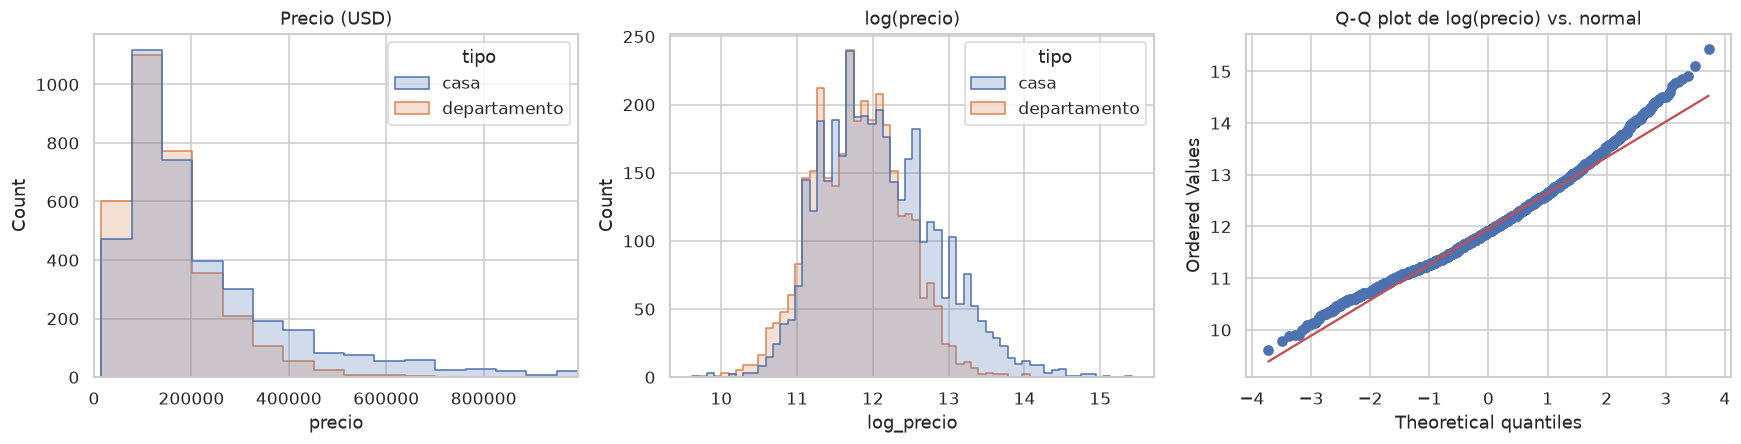

,asimetría,curtosis (exceso)
precio,6.04,74.28
log(precio),0.50,0.48


Percentiles de precio (USD): {0.01: 40000, 0.25: 94000, 0.5: 149000, 0.75: 240000, 0.99: 994000}


In [11]:
df["log_precio"] = np.log(df[TARGET])
df["log_precio_m2"] = np.log(df["precio_m2"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(data=df, x=TARGET, hue="tipo", bins=80, element="step", ax=axes[0])
axes[0].set(title="Precio (USD)", xlim=(0, df[TARGET].quantile(0.99)))
axes[0].ticklabel_format(style="plain", axis="x")
sns.histplot(data=df, x="log_precio", hue="tipo", bins=60, element="step", ax=axes[1])
axes[1].set(title="log(precio)")
stats.probplot(df["log_precio"], dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot de log(precio) vs. normal")
plt.tight_layout(); plt.show()

resumen = pd.DataFrame({
    "asimetría": [df[TARGET].skew(), df["log_precio"].skew()],
    "curtosis (exceso)": [df[TARGET].kurt(), df["log_precio"].kurt()],
}, index=["precio", "log(precio)"]).round(2)
display(resumen)
print("Percentiles de precio (USD):",
      df[TARGET].quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(-3).astype(int).to_dict())

_Comentario:_ la asimetría pasa de 6,0 a 0,5 y la curtosis en exceso de 74 a 0,5 al tomar logaritmo; el Q-Q plot de
log(precio) es casi lineal salvo en las colas (algo más pesada la derecha: propiedades de lujo). El 98 % central de
los precios va de USD 40.000 a USD 994.000, un rango de 25 veces. (Con n ≈ 7000 una
prueba formal como Shapiro-Wilk rechaza la normalidad por desviaciones mínimas, por eso se juzga visualmente.)

**Decisión:** el modelo se entrena sobre **log(precio)** y se evalúa con **RMSLE** (RMSE en escala log ≈ error
relativo), coherente con lo que el modelo minimiza.

### 4.6 Precio vs. área construida

Si el precio es multiplicativo, la relación en escala log-log debe ser aproximadamente lineal. La pendiente es la
**elasticidad**: cuánto sube el precio (%) cuando el área sube 1 %.

casa          elasticidad = 0.84 | R² log-log = 0.58
departamento  elasticidad = 0.66 | R² log-log = 0.44


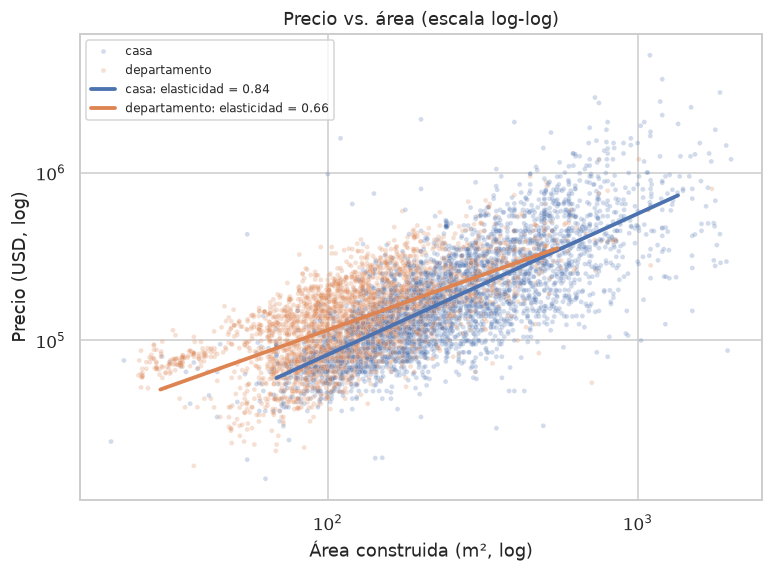

In [12]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="area_construida_m2", y=TARGET, hue="tipo", alpha=0.25, s=10, ax=ax)
for i, (t, g) in enumerate(df.groupby("tipo")):
    b, a = np.polyfit(np.log(g["area_construida_m2"]), g["log_precio"], 1)
    xs = np.linspace(g["area_construida_m2"].quantile(0.01), g["area_construida_m2"].quantile(0.99), 50)
    ax.plot(xs, np.exp(a) * xs ** b, c=f"C{i}", lw=2.5, label=f"{t}: elasticidad = {b:.2f}")
    r = np.corrcoef(np.log(g["area_construida_m2"]), g["log_precio"])[0, 1]
    print(f"{t:13s} elasticidad = {b:.2f} | R² log-log = {r ** 2:.2f}")
ax.set(xscale="log", yscale="log", xlabel="Área construida (m², log)", ylabel="Precio (USD, log)",
       title="Precio vs. área (escala log-log)")
ax.legend(fontsize=8); plt.show()

_Comentario:_ la relación es aproximadamente lineal en escala log-log. Las elasticidades son 0,84 (casas) y 0,66
(departamentos): duplicar el área sube el precio ≈ 79 % en casas y ≈ 58 % en departamentos, es decir, el precio por m²
baja a medida que la vivienda es más grande, y más en departamentos. El área sola explica el 58 % (casas) y el 44 %
(departamentos) de la varianza de log(precio): el resto debe venir de la ubicación y las demás características.

### 4.7 Ubicación: zonas

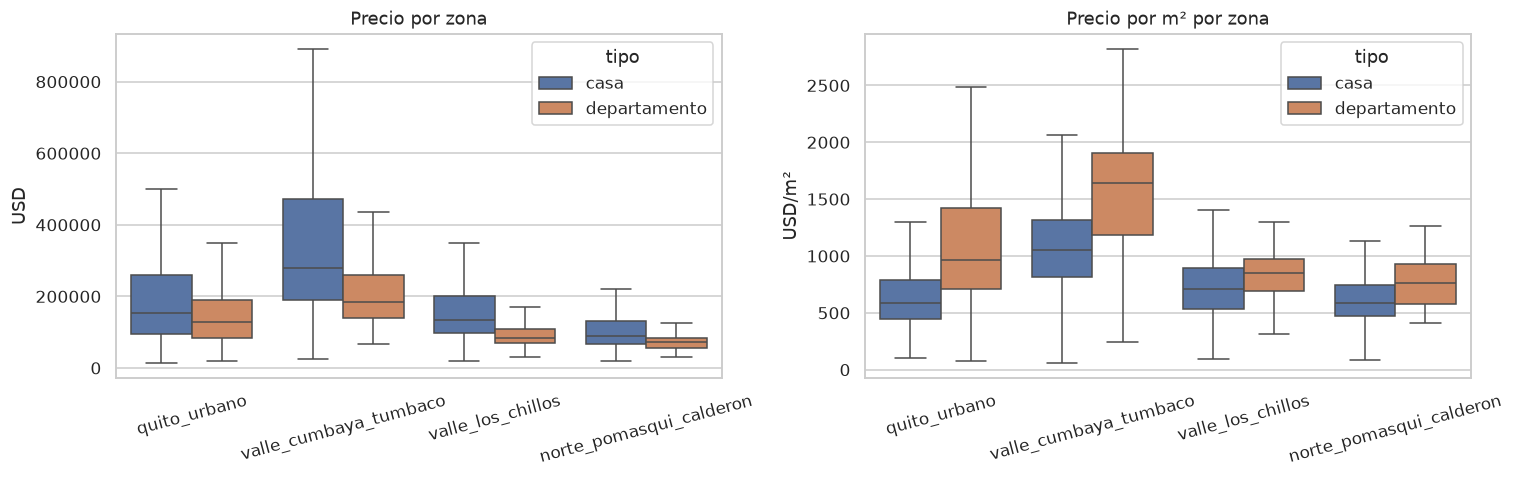

median              count             
tipo                       casa departamento  casa departamento
zona                                                           
quito_urbano              584.0        965.0  1286         2385
valle_cumbaya_tumbaco    1052.0       1645.0  1050          623
valle_los_chillos         706.0        852.0   984          171
norte_pomasqui_calderon   588.0        759.0   491           75

In [13]:
orden_zonas = ["quito_urbano", "valle_cumbaya_tumbaco", "valle_los_chillos", "norte_pomasqui_calderon"]
d = df[df["zona"].isin(orden_zonas)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=d, x="zona", y=TARGET, hue="tipo", order=orden_zonas, showfliers=False, ax=axes[0])
axes[0].set(title="Precio por zona", xlabel="", ylabel="USD")
sns.boxplot(data=d, x="zona", y="precio_m2", hue="tipo", order=orden_zonas, showfliers=False, ax=axes[1])
axes[1].set(title="Precio por m² por zona", xlabel="", ylabel="USD/m²")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

display(d.pivot_table(index="zona", columns="tipo", values="precio_m2", aggfunc=["median", "count"])
        .reindex(orden_zonas).round(0))

_Comentario:_ Cumbayá–Tumbaco es la zona más cara por m² (mediana USD 1.052 en casas y 1.645 en departamentos, frente
a 584 y 965 en Quito urbano); Los Chillos y Pomasqui–Calderón son las más baratas. En todas las zonas el departamento
cuesta más por m² que la casa. La zona sola explica solo el 15 % de la varianza de log(precio/m²), así que hace falta
una ubicación más fina (sección 4.8).

### 4.8 Ubicación: sectores y coordenadas

`sector` tiene muchas categorías. Para decidir cómo codificarlo se analiza:
1. cuántos anuncios tiene cada sector (categorías raras → one-hot disperso);
2. cuánta variación del precio por m² explica el sector frente a la zona (η², proporción de varianza explicada por
   las medias de grupo);
3. si el precio cambia de forma **suave en el espacio** (sectores vecinos con precios parecidos). Si es así, el sector
   se puede representar por las **coordenadas de su centroide** (2 columnas numéricas), lo que además permite dar
   ubicación a los anuncios sin coordenadas.

Sectores: 118 | con ≥ 10 anuncios: 75 (cubren 97.4% de las filas) | con < 5: 25

Varianza de log(precio/m²) explicada (η²):
  tipo            η² = 0.146
  zona            η² = 0.149
  sector          η² = 0.429
  tipo × zona     η² = 0.304
  tipo × sector   η² = 0.485


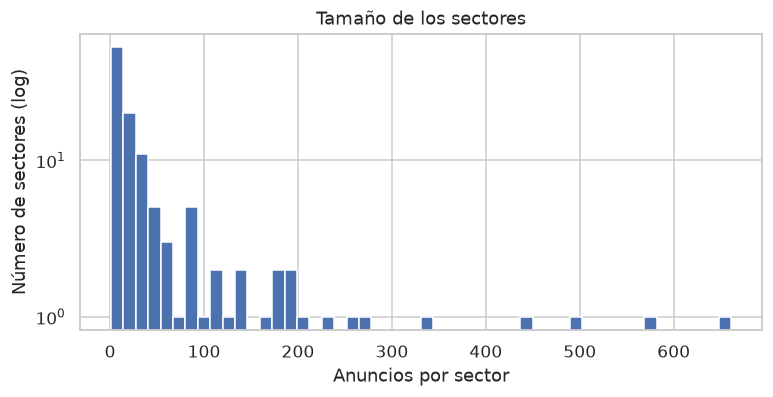

In [14]:
def eta2(y, grupos):
    # Proporción de la varianza de y explicada por las medias de cada grupo
    medias = y.groupby(grupos).transform("mean")
    return 1 - ((y - medias) ** 2).sum() / ((y - y.mean()) ** 2).sum()


n_sector = df["sector"].value_counts()
print(f"Sectores: {len(n_sector)} | con ≥ 10 anuncios: {(n_sector >= 10).sum()} "
      f"(cubren {n_sector[n_sector >= 10].sum() / len(df):.1%} de las filas) | con < 5: {(n_sector < 5).sum()}")

y_pm2 = df["log_precio_m2"]
print("\nVarianza de log(precio/m²) explicada (η²):")
for nombre, g in [("tipo", df["tipo"]), ("zona", df["zona"]), ("sector", df["sector"]),
                  ("tipo × zona", df["tipo"] + df["zona"].fillna("")),
                  ("tipo × sector", df["tipo"] + df["sector"].fillna(""))]:
    print(f"  {nombre:15s} η² = {eta2(y_pm2, g):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
n_sector.plot.hist(bins=50, ax=ax, log=True)
ax.set(xlabel="Anuncios por sector", ylabel="Número de sectores (log)", title="Tamaño de los sectores")
plt.show()

Anuncios sin coordenadas: 20 | de ellos, su sector tiene centroide: 19
Sectores sin ningún anuncio con coordenadas: 0 (0 filas): []

Correlación precio/m² del sector vs. sus 3 vecinos más cercanos: r = 0.77 (75 sectores)


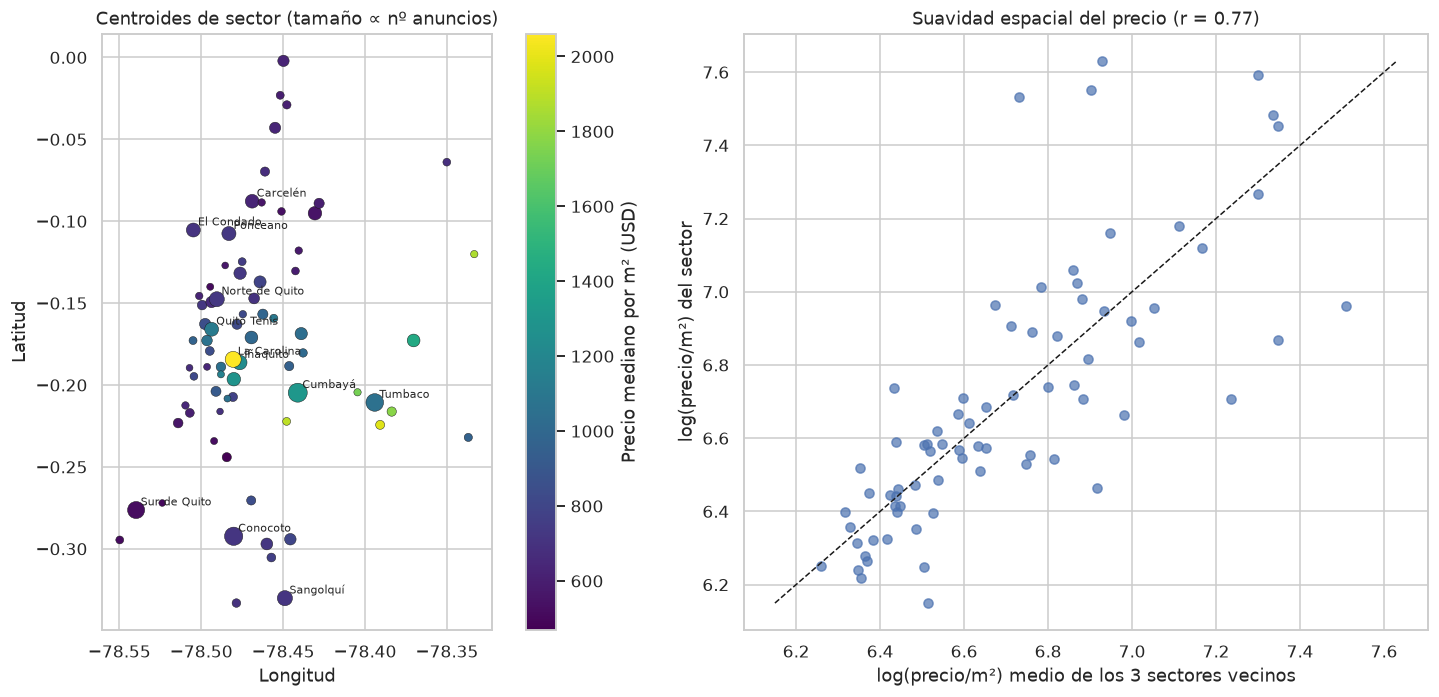

In [15]:
from scipy.spatial import cKDTree

# Centroide de cada sector (mediana de coordenadas de sus anuncios) y su precio/m² mediano
con_coord = df.dropna(subset=["latitud", "longitud"])
sectores = df.groupby("sector").agg(n=("precio", "size"), log_pm2=("log_precio_m2", "median")).join(
    con_coord.groupby("sector")[["latitud", "longitud"]].median())
sin_centroide = sectores["latitud"].isna()
filas_sin_coord = df["latitud"].isna()
print(f"Anuncios sin coordenadas: {filas_sin_coord.sum()} | de ellos, su sector tiene centroide: "
      f"{(~df.loc[filas_sin_coord, 'sector'].map(sectores['latitud']).isna()).sum()}")
print(f"Sectores sin ningún anuncio con coordenadas: {sin_centroide.sum()} "
      f"({sectores.loc[sin_centroide, 'n'].sum()} filas): {list(sectores.index[sin_centroide])[:10]}")

# Suavidad espacial: precio del sector vs. promedio de sus 3 sectores más cercanos
s = sectores[(sectores["n"] >= 10) & ~sin_centroide].copy()
xy = np.c_[s["latitud"], s["longitud"]]
_, vecinos = cKDTree(xy).query(xy, k=4)
s["log_pm2_vecinos"] = s["log_pm2"].values[vecinos[:, 1:]].mean(axis=1)
r = s[["log_pm2", "log_pm2_vecinos"]].corr().iloc[0, 1]
print(f"\nCorrelación precio/m² del sector vs. sus 3 vecinos más cercanos: r = {r:.2f} ({len(s)} sectores)")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
sc = axes[0].scatter(s["longitud"], s["latitud"], c=np.exp(s["log_pm2"]), s=np.sqrt(s["n"]) * 6,
                     cmap="viridis", edgecolor="k", lw=0.3)
plt.colorbar(sc, ax=axes[0], label="Precio mediano por m² (USD)")
for nombre, fila in s.nlargest(12, "n").iterrows():
    axes[0].annotate(nombre, (fila["longitud"], fila["latitud"]), fontsize=7, xytext=(3, 3),
                     textcoords="offset points")
axes[0].set(title="Centroides de sector (tamaño ∝ nº anuncios)", xlabel="Longitud", ylabel="Latitud")
axes[0].set_aspect("equal")
axes[1].scatter(s["log_pm2_vecinos"], s["log_pm2"], alpha=0.7)
lim = [s[["log_pm2", "log_pm2_vecinos"]].min().min(), s[["log_pm2", "log_pm2_vecinos"]].max().max()]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set(xlabel="log(precio/m²) medio de los 3 sectores vecinos", ylabel="log(precio/m²) del sector",
            title=f"Suavidad espacial del precio (r = {r:.2f})")
plt.tight_layout(); plt.show()

Puntos compartidos por ≥ 5 anuncios: 150, que agrupan 1886 anuncios (26.7% de los que tienen coordenadas)


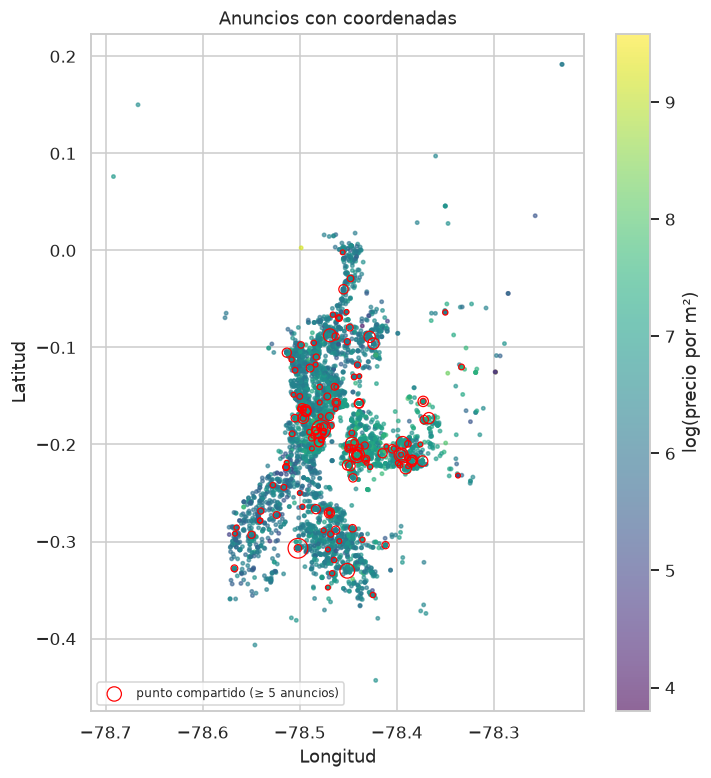

In [16]:
# Coordenadas compartidas: muchos anuncios en el mismo punto = centroide geocodificado del barrio, no la casa
conteo = con_coord.groupby(["latitud", "longitud"]).size()
compartidas = conteo[conteo >= 5]
print(f"Puntos compartidos por ≥ 5 anuncios: {len(compartidas)}, que agrupan {compartidas.sum()} anuncios "
      f"({compartidas.sum() / len(con_coord):.1%} de los que tienen coordenadas)")

fig, ax = plt.subplots(figsize=(7.5, 8))
sc = ax.scatter(con_coord["longitud"], con_coord["latitud"], c=con_coord["log_precio_m2"], cmap="viridis",
                s=5, alpha=0.6)
pts = compartidas.reset_index()
ax.scatter(pts["longitud"], pts["latitud"], s=pts[0] * 2, facecolor="none", edgecolor="red", lw=0.8,
           label="punto compartido (≥ 5 anuncios)")
plt.colorbar(sc, ax=ax, label="log(precio por m²)")
ax.set(xlabel="Longitud", ylabel="Latitud", title="Anuncios con coordenadas")
ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=8)
plt.show()

_Comentario / decisión sobre `sector`:_ hay 118 sectores; los 75 con al menos 10 anuncios cubren el 97,4 % de las
filas. El sector explica el 43 % de la varianza de log(precio/m²) (la zona, el 15 %; tipo × sector, el 49 %), y el
precio es espacialmente suave: el precio por m² de un sector correlaciona r = 0,77 con el de sus 3 vecinos. Opciones:

| Opción | Columnas | Ventajas | Desventajas |
|---|---|---|---|
| One-hot (sectores raros agrupados) | ~75 | simple, interpretable | disperso; ignora que sectores vecinos se parecen |
| Coordenadas del centroide del sector | 2 | usa la suavidad espacial; ubica a los anuncios sin coordenadas; sin información del objetivo | pierde diferencias entre sectores vecinos con precios distintos |
| Target encoding | 1 | compacto, muy informativo | usa el objetivo (requiere *cross-fitting*), más difícil de explicar |

**Decisión:** combinar las dos primeras. One-hot de `sector` con los sectores de menos de 10 anuncios agrupados
(conserva diferencias entre sectores vecinos) **y** latitud/longitud, donde los anuncios sin coordenadas reciben el
centroide de su sector, más la distancia al Parque La Carolina. El *target encoding* se descarta: requiere
*cross-fitting* para no filtrar el objetivo y es más difícil de explicar, sin una ganancia clara con 75 sectores
frecuentes.

### 4.9 Fuente de los datos

`fuente` no se usa como variable predictora (es trazabilidad), pero sirve para detectar si alguna fuente es poco
confiable. Para comparar fuentes de forma justa se usa el **residuo** de log(precio/m²) respecto a la mediana de su
mismo **sector y tipo**: así no se confunde “la fuente es cara” con “la fuente tiene más anuncios en Cumbayá”.

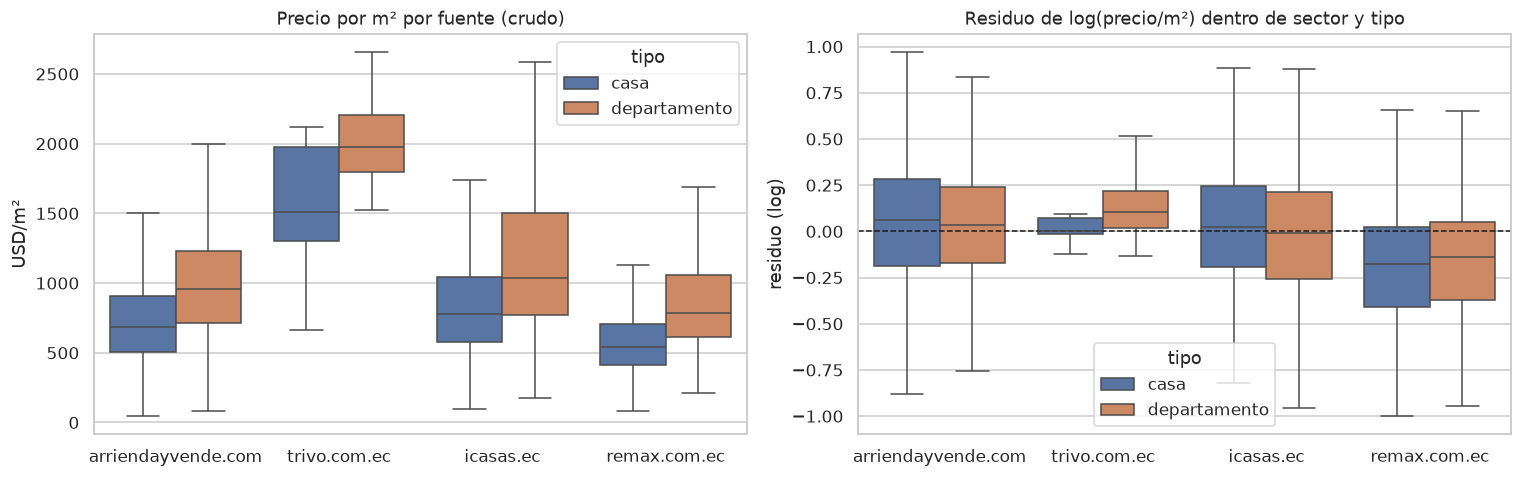

,median,count,diferencia %
fuente,,,
arriendayvende.com,0.046,1221,4.710
icasas.ec,0.004,4226,0.362
remax.com.ec,-0.158,1230,-14.592
trivo.com.ec,0.093,380,9.793


Proyectos nuevos (es_desarrollo=1) vs. resto, mismo sector y tipo: +11 %
Año de publicación en arriendayvende: {2019: 4, 2020: 40, 2021: 367, 2022: 779, 2023: 21, 2024: 9, 2026: 1}


In [17]:
df["resid_pm2"] = df["log_precio_m2"] - df.groupby(["sector", "tipo"])["log_precio_m2"].transform("median")

d = df[df["fuente"].isin(fuentes_principales)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=d, x="fuente", y="precio_m2", hue="tipo", showfliers=False, ax=axes[0])
axes[0].set(title="Precio por m² por fuente (crudo)", xlabel="", ylabel="USD/m²")
sns.boxplot(data=d, x="fuente", y="resid_pm2", hue="tipo", showfliers=False, ax=axes[1])
axes[1].axhline(0, c="k", ls="--", lw=1)
axes[1].set(title="Residuo de log(precio/m²) dentro de sector y tipo", xlabel="", ylabel="residuo (log)")
plt.tight_layout(); plt.show()

tabla = d.groupby("fuente")["resid_pm2"].agg(["median", "count"])
tabla["diferencia %"] = (np.exp(tabla["median"]) - 1) * 100
display(tabla.round(3))

g = df.groupby("es_desarrollo")["resid_pm2"].median()
print(f"Proyectos nuevos (es_desarrollo=1) vs. resto, mismo sector y tipo: {(np.exp(g[1] - g[0]) - 1) * 100:+.0f} %")
if "fecha_publicacion" in df:
    anios = pd.to_datetime(df.loc[df["fuente"] == "arriendayvende.com", "fecha_publicacion"]).dt.year
    print("Año de publicación en arriendayvende:", anios.value_counts().sort_index().to_dict())

_Comentario / decisión:_ dentro del mismo sector y tipo, RE/MAX está ≈ 15 % por debajo de la mediana, Trivo ≈ 10 % por
encima, arriendayvende ≈ 5 % por encima e icasas en la mediana. Aunque el 94 % de los anuncios de arriendayvende es de
2021–2022, su desviación es pequeña, así que no hay motivo para filtrarlo. La diferencia de RE/MAX podría deberse al
perfil de su cartera o a precios más cercanos al cierre, pero con estos datos no se puede verificar. **No se filtra
ninguna fuente.** Diferencias moderadas entre portales son esperables (cada portal tiene su público); la
diferencia de los proyectos nuevos es real y se captura con `es_desarrollo`.

### 4.10 Variables numéricas

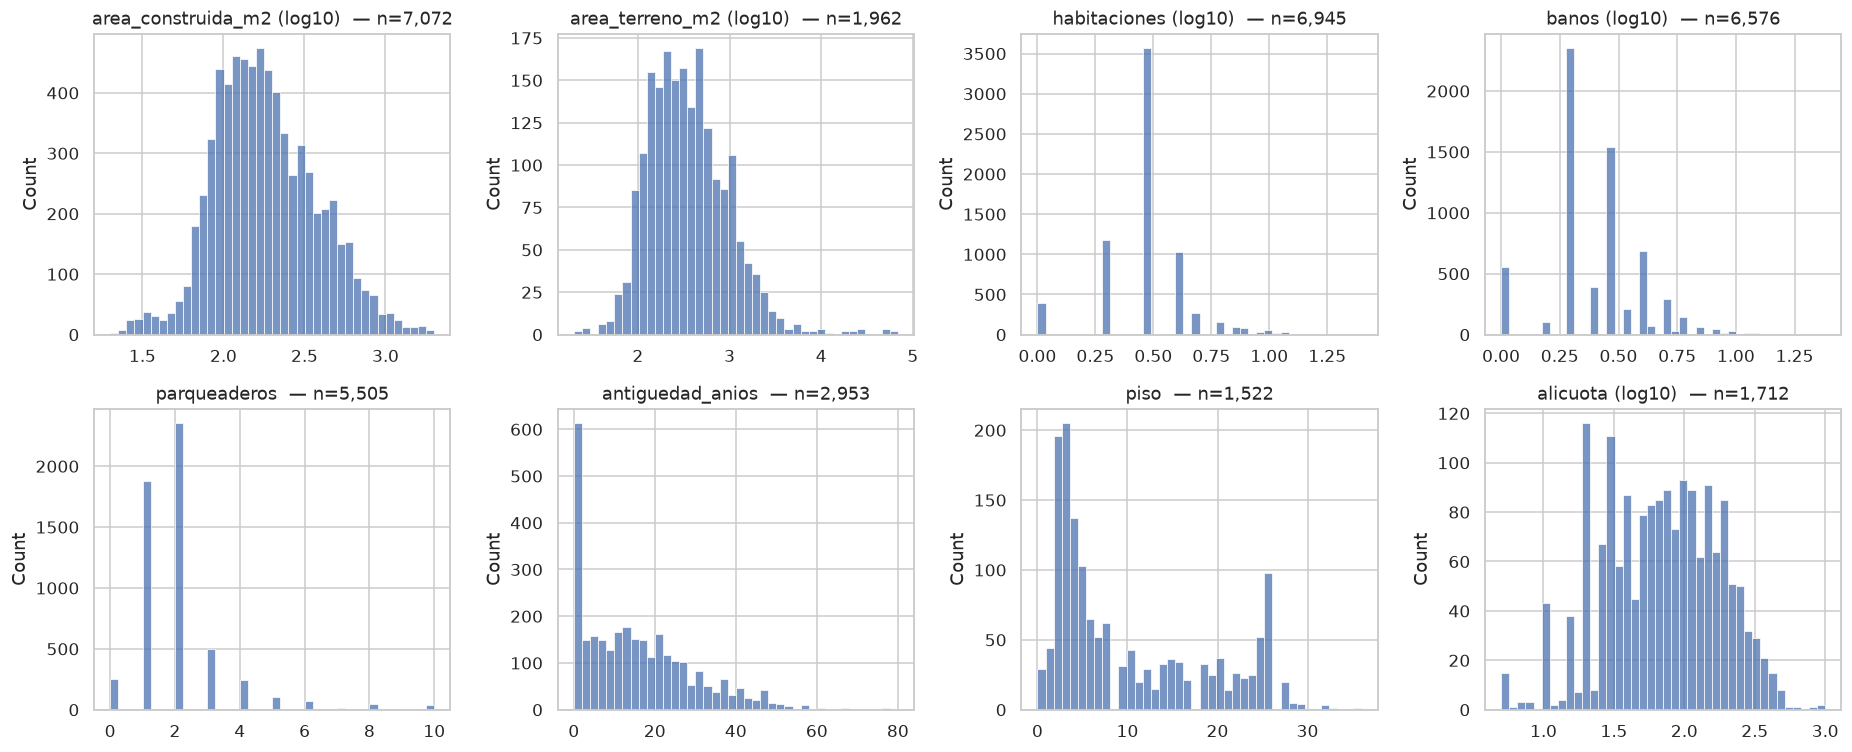

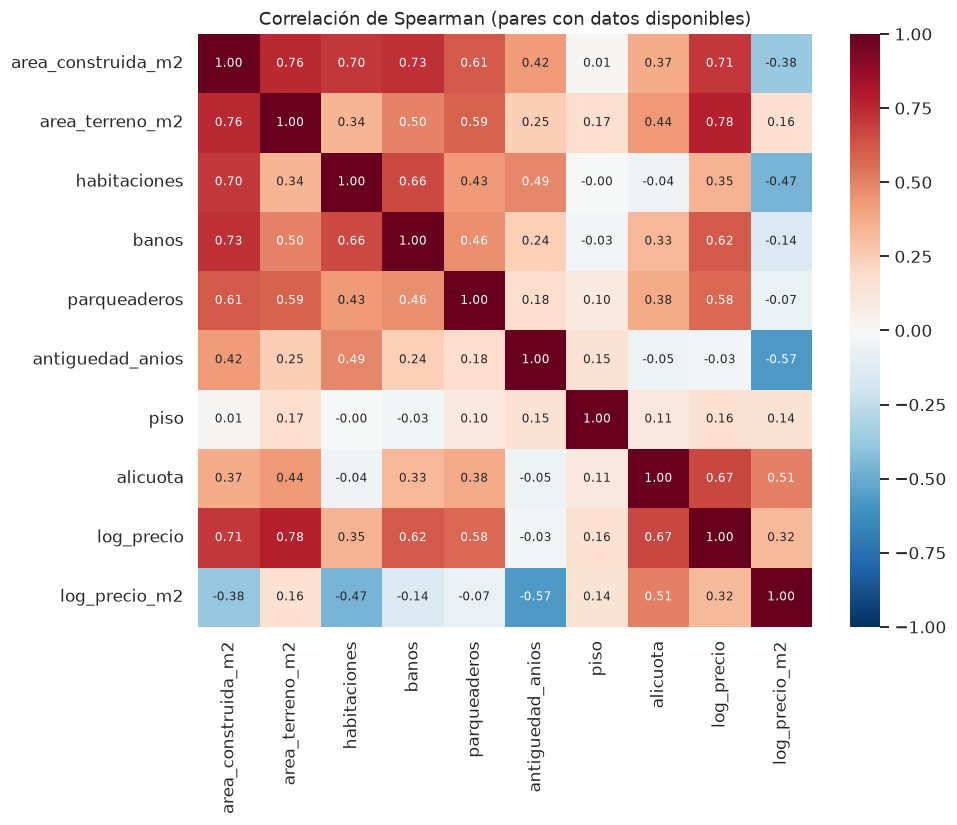

In [18]:
num_eda = ["area_construida_m2", "area_terreno_m2", "habitaciones", "banos", "parqueaderos",
           "antiguedad_anios", "piso", "alicuota"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.flat, num_eda):
    x = df[c].dropna()
    usar_log = x.min() > 0 and x.skew() > 2
    sns.histplot(np.log10(x) if usar_log else x, bins=40, ax=ax)
    ax.set(title=f"{c}{' (log10)' if usar_log else ''}  — n={len(x):,}", xlabel="")
plt.tight_layout(); plt.show()

corr = df[num_eda + ["log_precio", "log_precio_m2"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación de Spearman (pares con datos disponibles)")
plt.show()

_Comentario:_ las variables de tamaño están muy correlacionadas entre sí (área–baños 0,73, área–habitaciones 0,70,
habitaciones–baños 0,66): hay redundancia, relevante para la selección de características. Con log(precio) las más
asociadas son área de terreno (0,78, solo casas con el dato), área construida (0,71), alícuota (0,67) y baños
(0,62). Con el precio por m², en cambio, la antigüedad (−0,57) y las habitaciones (−0,47) son negativas: a igual
área, más habitaciones significa espacios más pequeños. `piso` casi no se relaciona con el precio.

### 4.11 ¿Los faltantes son informativos?

Si el precio difiere según si una variable falta o no, la ausencia contiene información y conviene agregar un
**indicador de faltante** en la imputación.

In [19]:
filas = []
for c in ["area_terreno_m2", "parqueaderos", "antiguedad_anios", "piso", "alicuota", "estado", "banos",
          "latitud"]:
    for t, g in df.groupby("tipo"):
        falta = g[c].isna()
        if 0.02 < falta.mean() < 0.98:
            filas.append({"variable": c, "tipo": t, "% faltante": 100 * falta.mean(),
                          "Δ residuo (faltante − presente) %":
                              (np.exp(g.loc[falta, "resid_pm2"].mean() - g.loc[~falta, "resid_pm2"].mean()) - 1) * 100})
pd.DataFrame(filas).set_index(["variable", "tipo"]).round(1)

% faltante  Δ residuo (faltante − presente) %
variable         tipo                                                       
area_terreno_m2  casa                49.0                                4.8
parqueaderos     casa                27.1                                4.0
                 departamento        16.3                                4.4
antiguedad_anios casa                59.2                               11.6
                 departamento        57.1                                3.6
piso             departamento        53.2                              -10.5
alicuota         casa                79.6                                4.9
                 departamento        71.4                               12.6
estado           casa                62.4                                6.4
                 departamento        56.1                                0.6
banos            casa                 3.5                                4.9
                 departamento        11.1                               19.3

In [ ]:
# ¿La diferencia se mantiene al comparar dentro de una misma fuente? (solo fuentes con ≥ 15 anuncios con y sin el dato)
filas = []
for c, t in [("banos", "departamento"), ("alicuota", "departamento"), ("antiguedad_anios", "casa"),
             ("piso", "departamento")]:
    g_tipo = df[df["tipo"] == t]
    for f, g in g_tipo[g_tipo["fuente"].isin(["icasas.ec", "remax.com.ec", "arriendayvende.com", "trivo.com.ec"])].groupby("fuente"):
        falta = g[c].isna()
        delta = np.nan
        if falta.sum() >= 15 and (~falta).sum() >= 15:
            delta = (np.exp(g.loc[falta, "resid_pm2"].mean() - g.loc[~falta, "resid_pm2"].mean()) - 1) * 100
        filas.append({"variable": c, "tipo": t, "fuente": f, "n": len(g), "% faltante": 100 * falta.mean(),
                      "Δ residuo (faltante − presente) %": delta})
pd.DataFrame(filas).set_index(["variable", "tipo", "fuente"]).round(1)

n  % faltante  \
variable         tipo         fuente                                 
banos            departamento arriendayvende.com   454         1.5   
                              icasas.ec           1900         1.4   
                              remax.com.ec         571         0.0   
                              trivo.com.ec         328       100.0   
alicuota         departamento arriendayvende.com   454        78.0   
                              icasas.ec           1900        79.1   
                              remax.com.ec         571        23.8   
                              trivo.com.ec         328       100.0   
antiguedad_anios casa         arriendayvende.com   767        25.8   
                              icasas.ec           2326        88.4   
                              remax.com.ec         666         0.9   
                              trivo.com.ec          52         0.0   
piso             departamento arriendayvende.com   454        88.3   
                              icasas.ec           1900        42.0   
                              remax.com.ec         571        77.8   
                              trivo.com.ec         328        26.8   

                                                  Δ residuo (faltante − presente) %  
variable         tipo         fuente                                                 
banos            departamento arriendayvende.com                                NaN  
                              icasas.ec                                        12.0  
                              remax.com.ec                                      NaN  
                              trivo.com.ec                                      NaN  
alicuota         departamento arriendayvende.com                               -2.4  
                              icasas.ec                                         8.3  
                              remax.com.ec                                      6.5  
                              trivo.com.ec                                      NaN  
antiguedad_anios casa         arriendayvende.com                                7.6  
                              icasas.ec                                         5.6  
                              remax.com.ec                                      NaN  
                              trivo.com.ec                                      NaN  
piso             departamento arriendayvende.com                               -4.0  
                              icasas.ec                                       -11.4  
                              remax.com.ec                                     -7.6  
                              trivo.com.ec                                     -1.6

_Comentario:_ hay diferencias de precio entre anuncios con y sin el dato, pero son **asociaciones, no efectos**: no
publicar el número de baños no hace que una vivienda valga más. La ausencia de un dato depende sobre todo de **la
fuente y del tipo de anuncio**. Por ejemplo, los departamentos sin baños son ≈ 19 % más caros por m² que los de su
mismo sector, pero casi todos son proyectos de Trivo (que nunca publica baños) y los proyectos nuevos son más caros.
Al comparar dentro de una misma fuente (segunda tabla), las diferencias se reducen (alícuota: de +13 % a entre
−2 % y +8 %; antigüedad en casas: de +12 % a +6–8 %), aunque no desaparecen del todo, probablemente por otras variables no
observadas (p. ej. qué tan completo es el anuncio). La excepción es `piso`: los departamentos sin piso son más baratos
en las cuatro fuentes (entre 2 % y 11 %), sin una explicación clara con estos datos.

**Decisión:** se mantiene el **indicador de faltante** (`add_indicator=True`) porque ayuda a predecir, no porque la
ausencia cause el precio: funciona como un *proxy* del tipo de anuncio y, en parte, de la fuente. Como `fuente` no es
predictor, esto reintroduce parcialmente información de la fuente en el modelo; para un ejercicio de predicción es
aceptable, pero impide interpretar estos indicadores de forma causal.

### 4.12 Amenidades y otras variables binarias

Diferencia de precio por m² entre anuncios con y sin cada característica, **dentro del mismo sector y tipo**
(media del residuo). Es una asociación, no un efecto causal: las amenidades suelen ir juntas.

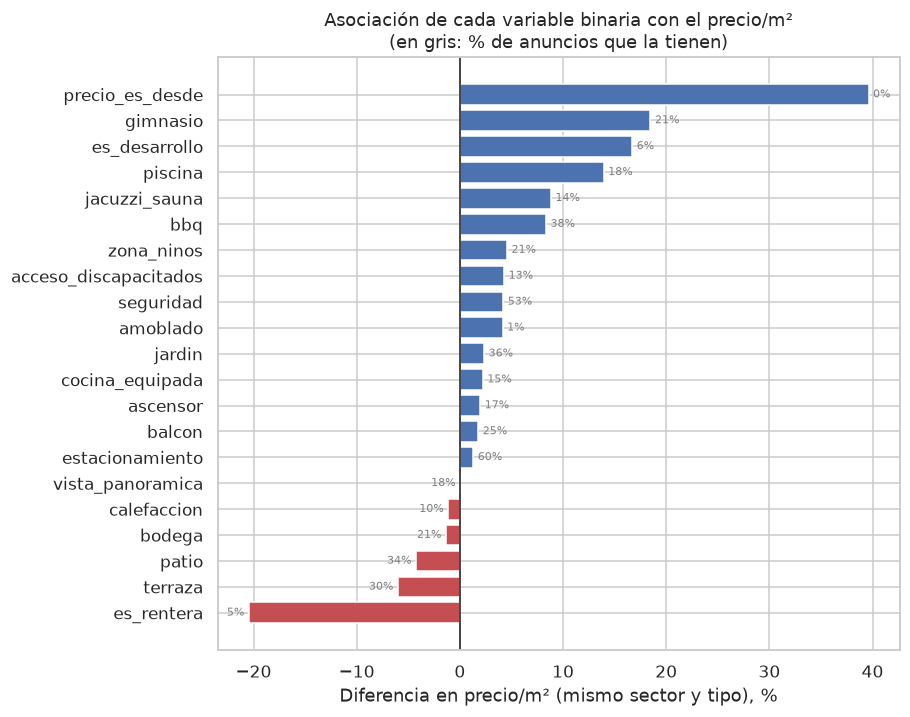

In [20]:
BINARIAS = ["piscina", "jardin", "gimnasio", "ascensor", "seguridad", "bbq", "terraza", "balcon", "bodega",
            "zona_ninos", "estacionamiento", "cocina_equipada", "calefaccion", "vista_panoramica", "patio",
            "jacuzzi_sauna", "acceso_discapacitados", "amoblado", "es_desarrollo", "precio_es_desde", "es_rentera"]
filas = []
for c in BINARIAS:
    m = df[c] == 1
    filas.append({"variable": c, "prevalencia %": 100 * m.mean(),
                  "diferencia %": (np.exp(df.loc[m, "resid_pm2"].mean() - df.loc[df[c] == 0, "resid_pm2"].mean())
                                   - 1) * 100})
amen = pd.DataFrame(filas).set_index("variable").sort_values("diferencia %")

fig, ax = plt.subplots(figsize=(8, 7))
colores = ["C3" if v < 0 else "C0" for v in amen["diferencia %"]]
ax.barh(amen.index, amen["diferencia %"], color=colores)
for i, (v, p) in enumerate(zip(amen["diferencia %"], amen["prevalencia %"])):
    ax.annotate(f"{p:.0f}%", (v, i), xytext=(3 if v >= 0 else -3, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontsize=7, color="gray")
ax.axvline(0, c="k", lw=1)
ax.set(xlabel="Diferencia en precio/m² (mismo sector y tipo), %",
       title="Asociación de cada variable binaria con el precio/m²\n(en gris: % de anuncios que la tienen)")
plt.show()

_Comentario:_ como en la sección anterior, son **asociaciones, no efectos**: las amenidades marcan el tipo de
vivienda más que agregar valor por sí mismas. Las mayores diferencias positivas son `precio_es_desde` (≈ +40 %, solo
filas de constructoras), gimnasio (≈ +18 %), `es_desarrollo` y piscina (≈ +14 %): características típicas de edificios
nuevos, así que un gimnasio indica sobre todo que el edificio es nuevo, no que el gimnasio valga un 18 %. Las casas
renteras cuestan ≈ 20 % menos por m² (mucha área de menor acabado), y terraza y patio aparecen asociados a precios
algo menores, probablemente porque son más comunes en viviendas antiguas o de zonas más baratas. Varias amenidades
tienen diferencias menores al 5 % y pueden ser poco útiles para el modelo.

### 4.13 Atípicos de precio por m²

El dataset marca (sin eliminar) los anuncios con precio/m² fuera de 1,5·IQR en escala log, por tipo.

In [21]:
atip = df[df["outlier_precio_m2"] == 1]
print(f"Atípicos marcados: {len(atip)} ({len(atip) / len(df):.1%})")
display(atip["fuente"].value_counts().to_frame("n"))
atip.sort_values("precio_m2")[["fuente", "tipo", "sector", "precio", "area_construida_m2", "precio_m2",
                                "titulo"]].iloc[np.r_[0:6, -6:0]]

Atípicos marcados: 66 (0.9%)


,n
fuente,
icasas.ec,34
remax.com.ec,19
arriendayvende.com,13


,fuente,tipo,sector,precio,area_construida_m2,precio_m2,titulo
1190,arriendayvende.com,casa,Carapungo,87000.0,1950.0,44.62,"Casa en venta sector San Jose de Moran, Quito,..."
726,arriendayvende.com,casa,Tumbaco,31000.0,496.0,62.50,"Casa en venta Tumbaco, Quito, Ecuador"
82,arriendayvende.com,departamento,Sur de Quito,56000.0,711.0,78.76,"Departamento en venta en Puengasi, Quito, Ecuador"
6504,remax.com.ec,casa,NaN,30000.0,350.0,85.71,EL TERRENO 250M2 EN CUZUBAMBA
5018,icasas.ec,casa,Conocoto,99900.0,1025.0,97.46,"Casa en Conocoto, Quito"
5590,icasas.ec,casa,El Quinche,80000.0,800.0,100.00,"Casa en Iguiñaro Park, Quito, Ecuador"
6834,remax.com.ec,casa,Calderón,750000.0,141.0,5319.15,CASA REMODELADA EN VENTA – CONJUNTO BONANZA
4058,icasas.ec,casa,Centro Histórico,650000.0,120.0,5416.67,"Casa en Centro Histórico, Quito"
319,arriendayvende.com,casa,La Armenia,429000.0,55.0,7800.00,"Casa de venta en la Armenia, Quito, Ecuador"
3092,icasas.ec,casa,Calacalí,980000.0,100.0,9800.00,"Casa en Calacalí, Norte De Quito"


_Comentario / decisión:_ se marcan 66 anuncios (0,9 %). Varios extremos parecen errores de área, p. ej. una casa de
1.950 m² a USD 87.000 (USD 45/m²) o casas de 100–120 m² a más de USD 5.000/m², que probablemente incluyen terreno o
tienen el área mal registrada. Otros pueden ser reales (propiedades de lujo, terrenos grandes). Como no hay un
criterio fiable para separar errores de casos reales, **se conservan**: son menos del 1 %, el modelo trabaja en
escala log (lo que reduce su influencia) y `outlier_precio_m2` no se usa como predictor porque se deriva del
objetivo.

### 4.14 Resumen del EDA y decisiones

| # | Hallazgo | Decisión para el pipeline |
|---|---|---|
| 1 | Precio muy asimétrico; log(precio) ≈ normal | Entrenar sobre log(precio); métrica RMSLE |
| 2 | Relación precio–área lineal en log-log, elasticidad < 1 | log de áreas y alícuota en el preprocesamiento común |
| 3 | Faltantes estructurales y, en algunos casos, informativos (por la fuente y el tipo de anuncio, no causales) | Imputar dentro del pipeline con indicador de faltante |
| 4 | Casas renteras con muchas habitaciones | Variable `es_rentera`; anomalías → NaN |
| 5 | Sector explica gran parte de la varianza; precio espacialmente suave (r ≈ 0,77) | One-hot de `sector` + coordenadas (faltantes → centroide del sector) + distancia a La Carolina |
| 6 | Proyectos nuevos ≈ 11 % más caros en el mismo sector y tipo | Incluir `es_desarrollo` |
| 7 | Diferencias moderadas entre fuentes en el mismo sector y tipo | No se filtra ninguna fuente; `fuente` no es predictor |
| 8 | Atípicos de precio/m² (0,9 %), algunos con área probablemente errónea | Se conservan; `outlier_precio_m2` no es predictor (deriva del objetivo) |

## 5. Preparación para el modelado

Decisiones tomadas en el EDA (sección 4.14):

- **Objetivo en escala log.** `y = log(precio)` se calcula **antes** de la partición. Es una transformación fija (no
  aprende nada de los datos), así que no hay *data leakage*. La métrica de validación es el RMSE sobre log(precio),
  es decir el **RMSLE**, que equivale aproximadamente a un error relativo. Solo al final (sección 11) se vuelve a USD.
- **Alcance:** se excluyen las 7 filas fuera de Quito y sus valles (`zona` = `rural_otro` o vacía).
- **Variables** (las mismas para todos los modelos):

| Grupo | Columnas | Transformación (dentro del pipeline) |
|---|---|---|
| Tamaño (asimétricas) | `area_construida_m2`, `area_terreno_m2`, `alicuota` | log → imputación (mediana) + indicador de faltante → escalado |
| Numéricas | `habitaciones`, `banos`, `parqueaderos`, `antiguedad_anios`, `piso` | imputación (mediana) + indicador de faltante → escalado |
| Ubicación | `latitud`, `longitud` (+ `sector`) | coordenadas faltantes → centroide del sector; + distancia a La Carolina → escalado |
| Binarias | amenidades, `es_desarrollo`, `precio_es_desde`, `es_rentera` | imputación (moda) |
| Categóricas | `sector`, `tipo`, `zona`, `estado`, `canton` | faltante → "desconocido" → one-hot (categorías con < 10 anuncios agrupadas) |

**No se usan como predictores:** `precio_m2`, `outlier_precio_m2` y las columnas auxiliares del EDA (se calculan con
el precio: *data leakage*), `fuente` (solo trazabilidad), `id`, `url`, textos y fechas.

**Feature extraction:** no aplica: los datos son tabulares (estructurados) y no se usa *transfer learning*.

In [22]:
df_modelo = df[df["zona"].isin(["quito_urbano", "valle_cumbaya_tumbaco", "valle_los_chillos",
                                "norte_pomasqui_calderon"])].reset_index(drop=True)
print(f"Filas para el modelado: {len(df_modelo):,} (se excluyen {len(df) - len(df_modelo)} fuera del alcance)")

LOG_COLS = ["area_construida_m2", "area_terreno_m2", "alicuota"]
NUM_COLS = ["habitaciones", "banos", "parqueaderos", "antiguedad_anios", "piso"]
UBIC_COLS = ["latitud", "longitud", "sector"]
BIN_COLS = BINARIAS                     # definidas en la sección 4.12
CAT_COLS = ["sector", "tipo", "zona", "estado", "canton"]
FEATURES = list(dict.fromkeys(LOG_COLS + NUM_COLS + UBIC_COLS + BIN_COLS + CAT_COLS))

X = df_modelo[FEATURES]
y = np.log(df_modelo[TARGET])           # objetivo en escala log (transformación fija, sin leakage)
print(f"{X.shape[1]} columnas de entrada")

Filas para el modelado: 7,065 (se excluyen 7 fuera del alcance)
36 columnas de entrada


## 6. Partición entrenamiento / prueba

Se reserva un 20 % de los datos como **conjunto de prueba**, que no se toca hasta la evaluación final. La partición se
estratifica por deciles de precio para que ambos conjuntos tengan la misma distribución del objetivo. Toda la
optimización y la comparación estadística se hacen con validación cruzada **sobre el conjunto de entrenamiento**.

_Limitación conocida:_ las unidades de un mismo proyecto de constructora (p. ej. 75 tipologías del proyecto Beat)
pueden quedar en folds distintos, lo que hace la validación algo optimista para esas filas. Se acepta para mantener el
esquema estándar de *repeated k-fold*.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=pd.qcut(y, 10, labels=False))
print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}")

Entrenamiento: 5,652 | Prueba: 1,413


## 7. Pipeline

Todo el flujo se encapsula en un `Pipeline` de `scikit-learn` [1]. La imputación, el escalado, la codificación, los
centroides de sector y la selección de características se **ajustan solo con los datos de entrenamiento de cada
fold**, sin *data leakage*. Los tres modelos reciben exactamente la misma entrada:

```
Pipeline
├── preprocesamiento (ColumnTransformer)
│   ├── tamaño:      log1p → SimpleImputer(mediana, indicador) → StandardScaler
│   ├── numéricas:   SimpleImputer(mediana, indicador) → StandardScaler
│   ├── ubicación:   ImputadorCoordenadas (centroide del sector + distancia a La Carolina) → StandardScaler
│   ├── binarias:    SimpleImputer(moda)
│   └── categóricas: SimpleImputer("desconocido") → OneHotEncoder(min_frequency=10)
├── varianza:  VarianceThreshold          ← descarta columnas constantes en el fold
├── seleccion: SelectPercentile(f_regression)   ← feature selection tipo filtro
└── modelo:    RegresorLightning (MLP en PyTorch Lightning) | RandomForestRegressor | Ridge (referencia)
```

**Feature selection (filtro):** `SelectPercentile` con `f_regression` calcula, para cada característica, el
estadístico F de una regresión lineal univariada contra log(precio) y conserva el percentil superior. Es un método de
tipo filtro porque evalúa cada variable por separado, sin usar el modelo. El percentil se optimiza con Optuna como un
hiperparámetro más.

**Logaritmos en variables:** el log de las áreas y la alícuota es necesario para Ridge (modelo hedónico log-log:
el coeficiente del área se interpreta como elasticidad) y ayuda a la MLP. No afecta al Random Forest, porque una
transformación monótona no cambia dónde corta un árbol. Así los tres modelos compiten con las mismas entradas.

### 7.1 Red neuronal (MLP) con PyTorch Lightning

La MLP se implementa con **PyTorch Lightning** [15], separando las responsabilidades en clases:

| Clase | Rol |
|---|---|
| `DatosPrecios` (`LightningDataModule`) | Convierte las matrices a tensores, separa un 10 % para validación (early stopping) y crea los `DataLoader` |
| `MLPPrecios` (`LightningModule`) | Arquitectura (capas lineales + ReLU), función de pérdida (MSE) y optimizador (Adam [9] con *weight decay* = regularización L2) |
| `MejorEstado` (`Callback`) | Guarda en memoria los pesos de la mejor época de validación y el historial de pérdidas |
| `RegresorLightning` | Adaptador con la interfaz de scikit-learn (`fit`/`predict`), para usar la red dentro del `Pipeline`, con Optuna y con *repeated k-fold* |

El `Trainer` detiene el entrenamiento cuando la pérdida de validación no mejora en `paciencia` épocas
(`EarlyStopping`) y se restauran los pesos de la mejor época. El objetivo se estandariza dentro de `fit` (media 0,
desviación 1): con log(precio) ≈ 12 la red gastaría épocas aprendiendo solo el desplazamiento. Con
`accelerator="auto"` la red usa la GPU si existe (p. ej. en Colab) y si no, la CPU.

In [24]:
import copy
import logging

import torch
import lightning as L
from lightning.pytorch.callbacks import Callback, EarlyStopping
from sklearn.base import BaseEstimator, RegressorMixin
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split


class DatosPrecios(L.LightningDataModule):
    def __init__(self, X, y, tamano_lote=64, fraccion_val=0.1, semilla=SEED):
        super().__init__()
        self.X = torch.as_tensor(X, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.float32).reshape(-1, 1)
        self.tamano_lote, self.fraccion_val, self.semilla = tamano_lote, fraccion_val, semilla

    def setup(self, stage=None):
        datos = TensorDataset(self.X, self.y)
        n_val = max(1, int(len(datos) * self.fraccion_val))
        self.entrenamiento, self.validacion = random_split(
            datos, [len(datos) - n_val, n_val], generator=torch.Generator().manual_seed(self.semilla))

    def train_dataloader(self):
        return DataLoader(self.entrenamiento, batch_size=self.tamano_lote, shuffle=True)

    def val_dataloader(self):
        return DataLoader(self.validacion, batch_size=1024)


class MLPPrecios(L.LightningModule):
    def __init__(self, n_entradas, capas_ocultas=(64, 32), tasa_aprendizaje=1e-3, weight_decay=1e-4):
        super().__init__()
        self.save_hyperparameters()
        capas, n = [], n_entradas
        for n_ocultas in capas_ocultas:
            capas += [nn.Linear(n, n_ocultas), nn.ReLU()]
            n = n_ocultas
        capas.append(nn.Linear(n, 1))
        self.red = nn.Sequential(*capas)
        self.perdida = nn.MSELoss()

    def forward(self, x):
        return self.red(x)

    def training_step(self, lote, _):
        x, y = lote
        perdida = self.perdida(self(x), y)
        self.log("train_loss", perdida, on_step=False, on_epoch=True)
        return perdida

    def validation_step(self, lote, _):
        x, y = lote
        self.log("val_loss", self.perdida(self(x), y), on_step=False, on_epoch=True)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.tasa_aprendizaje,
                                weight_decay=self.hparams.weight_decay)


class MejorEstado(Callback):
    # Guarda los pesos de la mejor época (menor val_loss) y el historial de pérdidas por época
    def __init__(self):
        self.mejor, self.estado, self.historial = float("inf"), None, []

    def on_validation_epoch_end(self, trainer, modulo):
        if trainer.sanity_checking:
            return
        val = trainer.callback_metrics["val_loss"].item()
        tr = trainer.callback_metrics.get("train_loss")
        self.historial.append({"epoca": trainer.current_epoch, "val_loss": val,
                               "train_loss": tr.item() if tr is not None else np.nan})
        if val < self.mejor:
            self.mejor, self.estado = val, copy.deepcopy(modulo.state_dict())


class RegresorLightning(BaseEstimator, RegressorMixin):
    # Adaptador scikit-learn: permite usar la MLP de Lightning dentro de Pipeline, Optuna y cross_val_score
    def __init__(self, hidden_layer_sizes=(64, 32), learning_rate=1e-3, weight_decay=1e-4, batch_size=64,
                 max_epochs=300, patience=20, random_state=SEED, accelerator="auto"):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.random_state = random_state
        self.accelerator = accelerator

    def fit(self, X, y):
        # Silenciar mensajes de Lightning (también en los procesos paralelos de joblib) y usar 1 hilo por
        # proceso: el paralelismo viene de los folds de CV (N_JOBS), no de cada red.
        logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
        warnings.filterwarnings("ignore", module="lightning")
        torch.set_num_threads(1)
        L.seed_everything(self.random_state, workers=True, verbose=False)

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        self.media_y_, self.desv_y_ = float(y.mean()), float(y.std())
        datos = DatosPrecios(X, (y - self.media_y_) / self.desv_y_, self.batch_size, semilla=self.random_state)
        self.modelo_ = MLPPrecios(X.shape[1], tuple(self.hidden_layer_sizes), self.learning_rate, self.weight_decay)
        mejor = MejorEstado()
        trainer = L.Trainer(max_epochs=self.max_epochs, accelerator=self.accelerator, devices=1,
                            callbacks=[EarlyStopping("val_loss", patience=self.patience), mejor],
                            logger=False, enable_checkpointing=False, enable_progress_bar=False,
                            enable_model_summary=False, deterministic=True)
        trainer.fit(self.modelo_, datamodule=datos)
        self.modelo_.load_state_dict(mejor.estado)
        self.historial_ = pd.DataFrame(mejor.historial)
        self.n_epocas_ = len(self.historial_)
        return self

    def predict(self, X):
        self.modelo_.eval()
        with torch.no_grad():
            x = torch.as_tensor(np.asarray(X, dtype=np.float32), device=self.modelo_.device)
            pred = self.modelo_(x).cpu().numpy().ravel()
        return pred * self.desv_y_ + self.media_y_


print("PyTorch", torch.__version__, "| Lightning", L.__version__, "| CUDA disponible:", torch.cuda.is_available())

PyTorch 2.15.0+cpu | Lightning 2.6.6 | CUDA disponible: False


In [25]:
from sklearn.base import BaseEstimator, TransformerMixin

CAROLINA = (-0.1807, -78.4848)   # Parque La Carolina, centro financiero de Quito


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


class ImputadorCoordenadas(BaseEstimator, TransformerMixin):
    # Completa latitud/longitud faltantes con el centroide (mediana) del sector, aprendido SOLO en entrenamiento.
    # Si el sector no tiene centroide, usa la mediana global. Agrega la distancia al Parque La Carolina.
    # Entrada: columnas [latitud, longitud, sector]. Salida: [latitud, longitud, dist_carolina_km].
    def fit(self, X, y=None):
        X = pd.DataFrame(X, columns=UBIC_COLS)
        con = X.dropna(subset=["latitud", "longitud"])
        self.centroides_ = con.groupby("sector")[["latitud", "longitud"]].median()
        self.global_ = con[["latitud", "longitud"]].median()
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=UBIC_COLS).reset_index(drop=True)
        c = X[["sector"]].join(self.centroides_, on="sector")
        lat = X["latitud"].fillna(c["latitud"]).fillna(self.global_["latitud"])
        lon = X["longitud"].fillna(c["longitud"]).fillna(self.global_["longitud"])
        return np.c_[lat, lon, haversine_km(lat, lon, *CAROLINA)].astype(float)

    def get_feature_names_out(self, input_features=None):
        return np.array(["latitud", "longitud", "dist_carolina_km"])


def crear_preprocesador():
    tamano = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                       ("escalar", StandardScaler())])
    num = Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                    ("escalar", StandardScaler())])
    ubic = Pipeline([("coordenadas", ImputadorCoordenadas()), ("escalar", StandardScaler())])
    binarias = SimpleImputer(strategy="most_frequent")
    cat = Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="desconocido")),
                    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                             sparse_output=False))])
    return ColumnTransformer([("tam", tamano, LOG_COLS), ("num", num, NUM_COLS), ("ubic", ubic, UBIC_COLS),
                              ("bin", binarias, BIN_COLS), ("cat", cat, CAT_COLS)],
                             verbose_feature_names_out=False)


MODELOS_BASE = {
    "MLP": RegresorLightning(),   # MLP en PyTorch Lightning (sección 7.1)
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
    "Ridge": Ridge(),
}


def crear_pipeline(nombre_modelo):
    return Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("varianza", VarianceThreshold()),
        ("seleccion", SelectPercentile(f_regression, percentile=100)),
        ("modelo", clone(MODELOS_BASE[nombre_modelo])),
    ])


crear_pipeline("MLP")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('varianza', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tam', ...), ('num', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

In [26]:
# Línea base: modelos con hiperparámetros por defecto (RMSLE = RMSE sobre log(precio))
cv_rapido = RepeatedKFold(n_splits=5, n_repeats=1, random_state=SEED)
for nombre in MODELOS_BASE:
    s = -cross_val_score(crear_pipeline(nombre), X_train, y_train, cv=cv_rapido, scoring=SCORING, n_jobs=N_JOBS)
    print(f"{nombre:13s} RMSLE = {s.mean():.4f} ± {s.std():.4f}  (≈ {100 * (np.exp(s.mean()) - 1):.0f} % de error típico)")

MLP           RMSLE = 0.2940 ± 0.0064  (≈ 34 % de error típico)


RandomForest  RMSLE = 0.2948 ± 0.0085  (≈ 34 % de error típico)


Ridge         RMSLE = 0.3040 ± 0.0060  (≈ 36 % de error típico)


124 características después del preprocesamiento


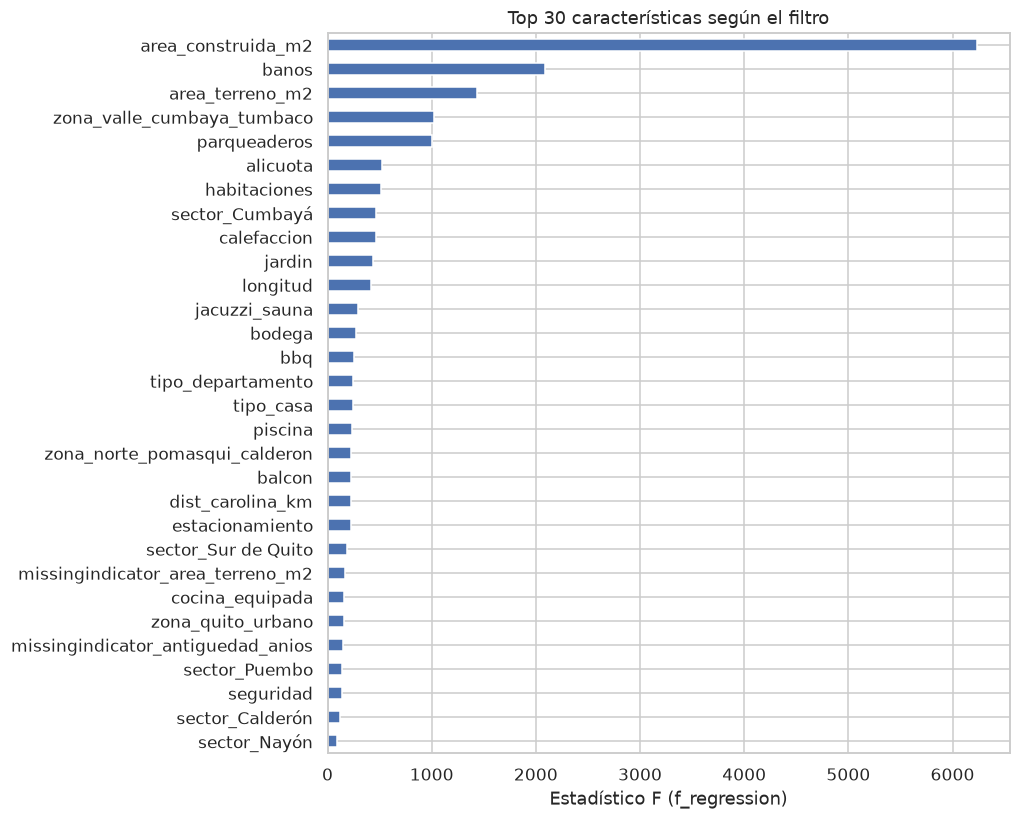

In [27]:
# Puntajes del filtro f_regression sobre todo el conjunto de entrenamiento (solo para interpretación)
pre = Pipeline([("preprocesamiento", crear_preprocesador()), ("varianza", VarianceThreshold())]).fit(X_train)
nombres_pre = pre[0].get_feature_names_out()[pre[1].get_support()]
F, _ = f_regression(pre.transform(X_train), y_train)
puntajes = pd.Series(F, index=nombres_pre).sort_values(ascending=False)
print(f"{len(puntajes)} características después del preprocesamiento")

fig, ax = plt.subplots(figsize=(8, 0.25 * 30 + 1))
puntajes.head(30).plot.barh(ax=ax)
ax.invert_yaxis()
ax.set(xlabel="Estadístico F (f_regression)", title="Top 30 características según el filtro")
plt.show()

## 8. Optimización de hiperparámetros con Optuna

Se optimizan los dos modelos de la comparación con Optuna [2] (muestreador TPE). Cada *trial* se evalúa con
**repeated k-fold CV** (`CV_OPT`) sobre el conjunto de entrenamiento, y se minimiza el **RMSLE**:

- **MLP** (perceptrón multicapa [7] en PyTorch [16] / Lightning [15], optimizador Adam [9]): número de capas ocultas
  (1–2), neuronas por capa, regularización L2 (`weight_decay`), tasa de aprendizaje y tamaño de lote. Usa *early
  stopping* con el 10 % del fold de entrenamiento y una red pequeña, porque hay ~5.600 filas de entrenamiento. El
  objetivo se estandariza dentro de `fit`: en una prueba preliminar (5 folds, MLP de scikit-learn) esto bajó el RMSLE
  de la red por defecto de 0,340 a 0,301.
- **Random Forest** [8]: número de árboles, profundidad máxima, mínimo de muestras por hoja y fracción de
  variables por división.
- **Ridge** [13] (referencia): solo `alpha`. Es el modelo hedónico lineal en log-log [12].

El percentil de la selección de características se optimiza junto con los hiperparámetros de cada modelo.

In [28]:
# Cada espacio devuelve directamente los parámetros del pipeline ("paso__parámetro")
def espacio_mlp(t):
    capas = [t.suggest_int("neuronas_1", 16, 256, log=True)]
    if t.suggest_int("n_capas", 1, 2) == 2:
        capas.append(t.suggest_int("neuronas_2", 8, 128, log=True))
    return {"seleccion__percentile": t.suggest_int("percentile", 30, 100, step=10),
            "modelo__hidden_layer_sizes": tuple(capas),
            "modelo__weight_decay": t.suggest_float("weight_decay", 1e-6, 1e-1, log=True),
            "modelo__learning_rate": t.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
            "modelo__batch_size": t.suggest_categorical("batch_size", [32, 64, 128])}


def espacio_rf(t):
    return {"seleccion__percentile": t.suggest_int("percentile", 30, 100, step=10),
            "modelo__n_estimators": t.suggest_int("n_estimators", 100, 500, step=50),
            "modelo__max_depth": t.suggest_int("max_depth", 4, 32, log=True),
            "modelo__min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 20, log=True),
            "modelo__max_features": t.suggest_float("max_features", 0.1, 1.0)}


def espacio_ridge(t):
    return {"seleccion__percentile": t.suggest_int("percentile", 30, 100, step=10),
            "modelo__alpha": t.suggest_float("alpha", 1e-3, 1e3, log=True)}


ESPACIOS = {"MLP": espacio_mlp, "RandomForest": espacio_rf, "Ridge": espacio_ridge}
N_TRIALS_MODELO = {"MLP": N_TRIALS, "RandomForest": N_TRIALS, "Ridge": max(10, N_TRIALS // 3)}


def optimizar(nombre_modelo):
    def objetivo(trial):
        modelo = crear_pipeline(nombre_modelo).set_params(**ESPACIOS[nombre_modelo](trial))
        scores = -cross_val_score(modelo, X_train, y_train, cv=CV_OPT, scoring=SCORING, n_jobs=N_JOBS)
        trial.set_user_attr("rmsle_std", scores.std())
        return scores.mean()

    estudio = optuna.create_study(direction="minimize", study_name=nombre_modelo,
                                  sampler=optuna.samplers.TPESampler(seed=SEED))
    estudio.optimize(objetivo, n_trials=N_TRIALS_MODELO[nombre_modelo], show_progress_bar=False)
    print(f"{nombre_modelo}: mejor RMSLE CV = {estudio.best_value:.4f} | {estudio.best_params}")
    return estudio


estudios = {nombre: optimizar(nombre) for nombre in ESPACIOS}

MLP: mejor RMSLE CV = 0.2857 | {'neuronas_1': 247, 'n_capas': 1, 'percentile': 90, 'weight_decay': 0.008157885249926526, 'learning_rate': 0.00016006401564074469, 'batch_size': 128}


RandomForest: mejor RMSLE CV = 0.2878 | {'percentile': 100, 'n_estimators': 500, 'max_depth': 30, 'min_samples_leaf': 1, 'max_features': 0.37441345664876524}


Ridge: mejor RMSLE CV = 0.3046 | {'percentile': 100, 'alpha': 0.784826171410592}


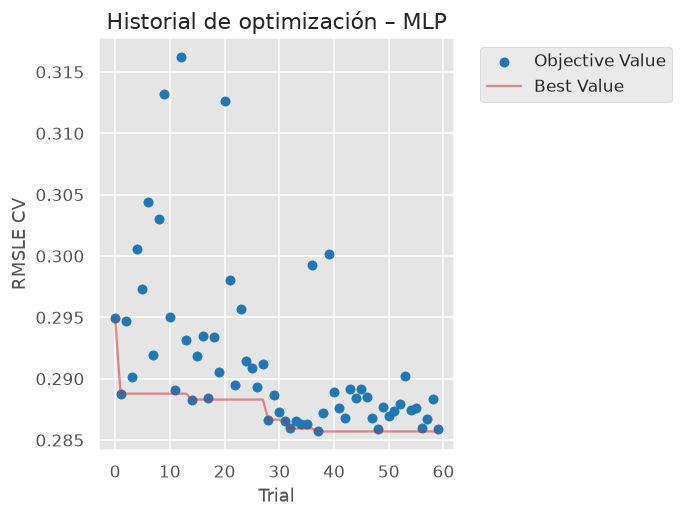

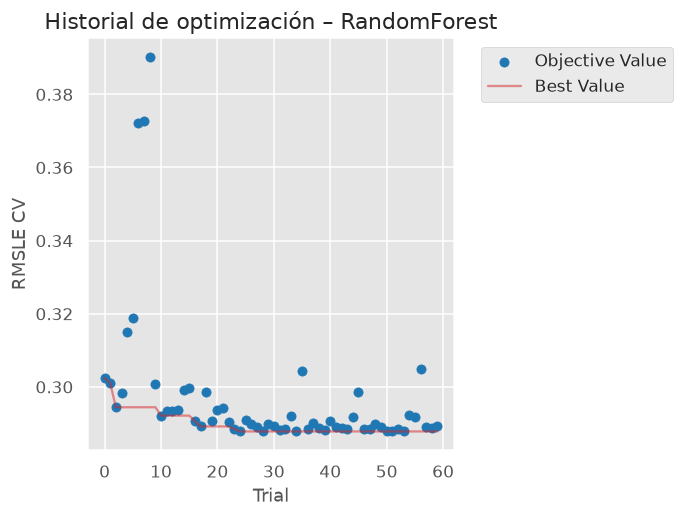

In [29]:
from optuna.visualization import matplotlib as ovm

PRINCIPALES = ["MLP", "RandomForest"]   # los dos modelos de la comparación estadística
for nombre in PRINCIPALES:
    ax = ovm.plot_optimization_history(estudios[nombre])
    ax.set_title(f"Historial de optimización – {nombre}")
    ax.set_ylabel("RMSLE CV")
    plt.show()

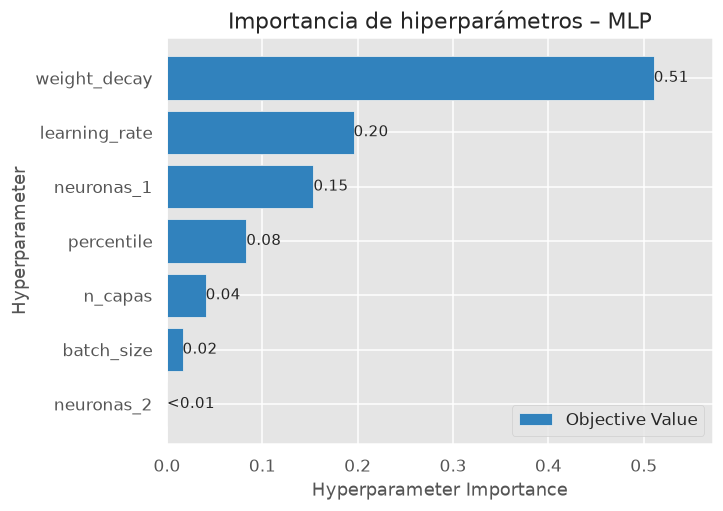

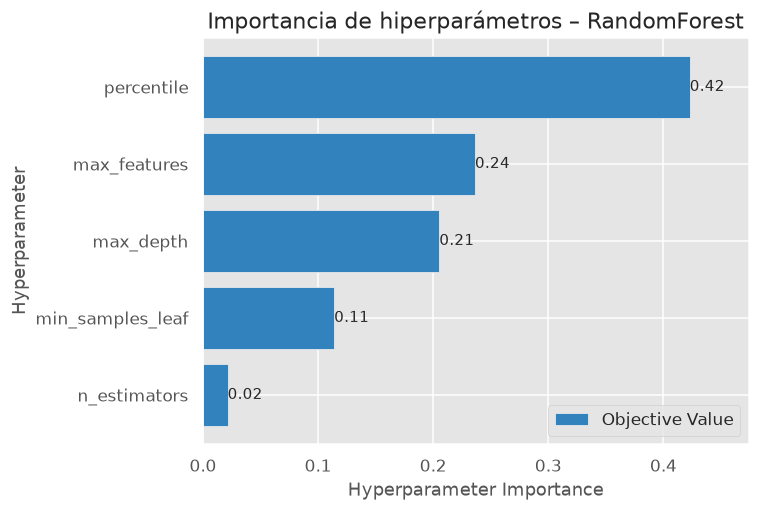

In [30]:
for nombre in PRINCIPALES:
    ax = ovm.plot_param_importances(estudios[nombre])
    ax.set_title("", loc="left")   # Optuna pone su propio título a la izquierda
    ax.set_title(f"Importancia de hiperparámetros – {nombre}")
    plt.show()

**Gráfica de la optimización de hiperparámetros:** cada punto es un *trial* de Optuna; el eje y es el RMSLE de
validación cruzada en función del valor de cada hiperparámetro (el color indica el número de trial).

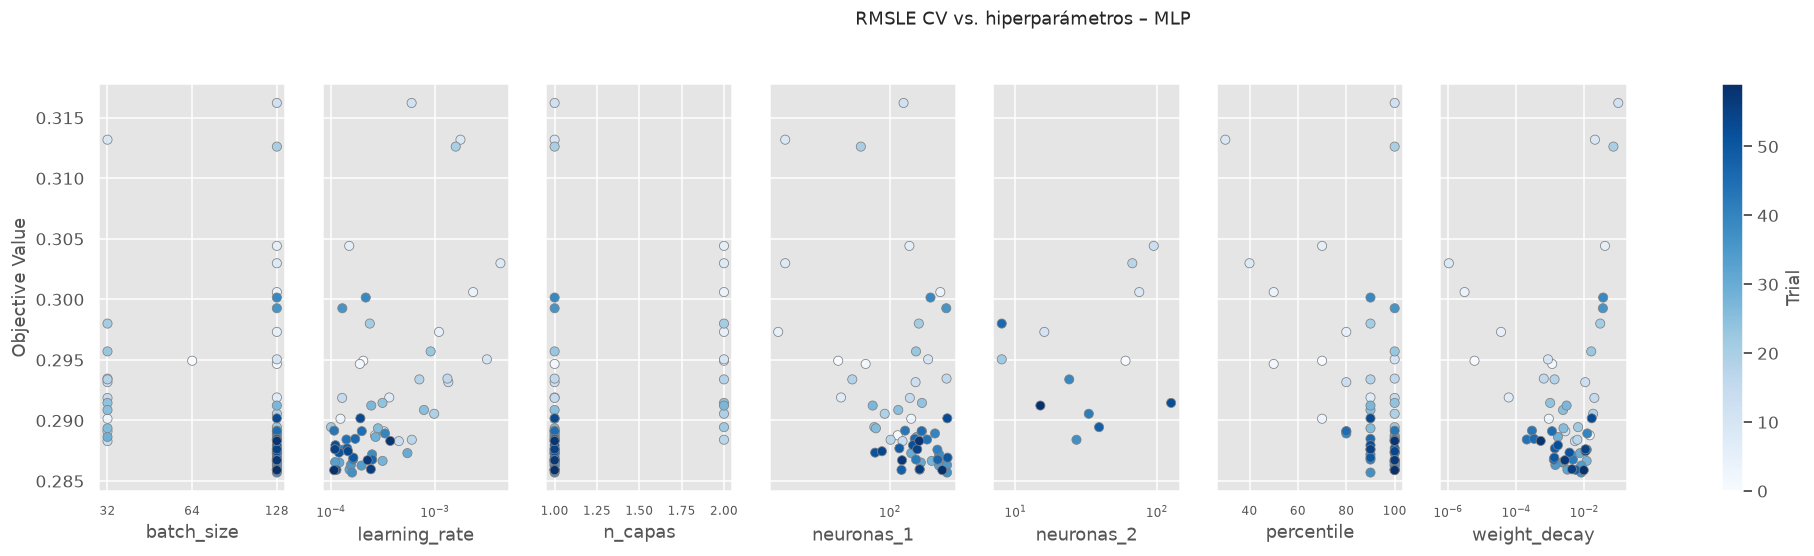

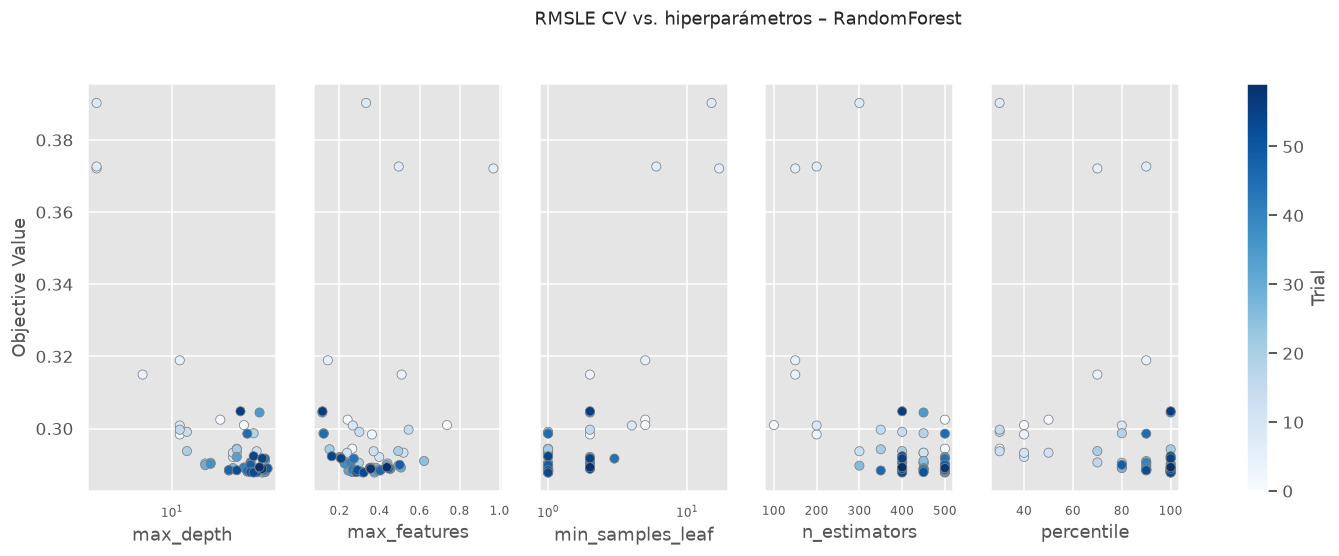

In [31]:
from matplotlib.ticker import NullFormatter

for nombre in PRINCIPALES:
    axes = ovm.plot_slice(estudios[nombre])
    for ax in np.atleast_1d(axes):
        ax.xaxis.set_minor_formatter(NullFormatter())   # evita etiquetas superpuestas en ejes log
        ax.tick_params(axis="x", labelsize=8)
    plt.suptitle(f"RMSLE CV vs. hiperparámetros – {nombre}", y=1.02)
    plt.show()

In [32]:
import json

# Mejores pipelines: se reconstruyen los parámetros con FixedTrial (maneja la capa oculta opcional de la MLP)
mejores = {n: crear_pipeline(n).set_params(**ESPACIOS[n](optuna.trial.FixedTrial(e.best_params)))
           for n, e in estudios.items()}

json.dump({n: e.best_params for n, e in estudios.items()},
          open(RESULTADOS / "mejores_hiperparametros.json", "w"), indent=2)
for n, e in estudios.items():
    e.trials_dataframe().to_csv(RESULTADOS / f"optuna_trials_{n}.csv", index=False)

pd.DataFrame({n: {"RMSLE CV": e.best_value, "Desv. est.": e.best_trial.user_attrs["rmsle_std"], **e.best_params}
              for n, e in estudios.items()}).T

,RMSLE CV,Desv. est.,neuronas_1,n_capas,percentile,weight_decay,learning_rate,batch_size,n_estimators,max_depth,min_samples_leaf,max_features,alpha
MLP,0.285699,0.005999,247.0,1.0,90.0,0.008158,0.00016,128.0,NaN,NaN,NaN,NaN,NaN
RandomForest,0.287807,0.008285,NaN,NaN,100.0,NaN,NaN,NaN,500.0,30.0,1.0,0.374413,NaN
Ridge,0.304618,0.007267,NaN,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.784826


_Comentario:_ en la MLP el hiperparámetro más importante es el *weight decay* (0,51), seguido de la tasa de
aprendizaje (0,20) y las neuronas de la primera capa (0,15). El óptimo es una sola capa de 247 neuronas, *weight
decay* ≈ 0,008, tasa de aprendizaje ≈ 1,6·10⁻⁴ y lotes de 128; la segunda capa no ayudó. En el RF lo más importante es
el percentil del filtro (0,42), luego `max_features` (0,24) y `max_depth` (0,21); el óptimo usa todas las
características, árboles profundos (`max_depth` = 30, `min_samples_leaf` = 1) y el 37 % de las variables en cada
división. Varios óptimos están en el borde del espacio de búsqueda (neuronas, tasa de aprendizaje, tamaño de lote,
`max_depth`, `min_samples_leaf`): ampliar esos rangos podría mejorar algo, aunque las curvas de la sección 9.1
muestran zonas bastante planas cerca del óptimo.

## 9. Curvas de validación y de aprendizaje

### 9.1 Curvas de validación

Se varía un hiperparámetro de cada modelo optimizado (los demás quedan en su valor óptimo) y se grafica el error de
entrenamiento y de validación (repeated k-fold CV). Permite ver el compromiso sesgo–varianza: en la MLP, la
regularización L2 (`weight_decay`); en el Random Forest, la profundidad máxima de los árboles.

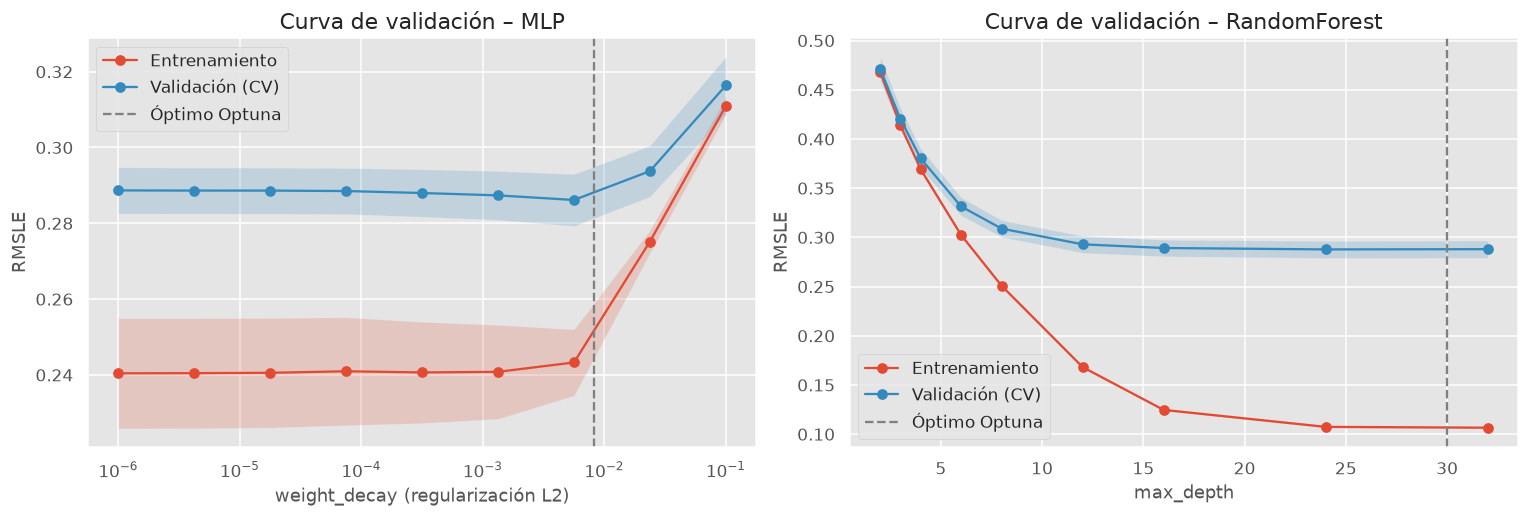

In [33]:
def a_rmsle(s):
    return -s.mean(axis=1), s.std(axis=1)


curvas = {
    "MLP": ("modelo__weight_decay", np.logspace(-6, -1, 9), "weight_decay (regularización L2)", "weight_decay", True),
    "RandomForest": ("modelo__max_depth", np.array([2, 3, 4, 6, 8, 12, 16, 24, 32]), "max_depth", "max_depth", False),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (nombre, (param, rango, etiqueta, clave, escala_log)) in zip(axes, curvas.items()):
    tr, va = validation_curve(mejores[nombre], X_train, y_train, param_name=param, param_range=rango,
                              cv=CV_OPT, scoring=SCORING, n_jobs=N_JOBS)
    (tr_m, tr_s), (va_m, va_s) = a_rmsle(tr), a_rmsle(va)
    ax.plot(rango, tr_m, "o-", label="Entrenamiento")
    ax.fill_between(rango, tr_m - tr_s, tr_m + tr_s, alpha=0.2)
    ax.plot(rango, va_m, "o-", label="Validación (CV)")
    ax.fill_between(rango, va_m - va_s, va_m + va_s, alpha=0.2)
    ax.axvline(estudios[nombre].best_params[clave], ls="--", c="gray", label="Óptimo Optuna")
    ax.set(xscale="log" if escala_log else "linear", xlabel=etiqueta, ylabel="RMSLE",
           title=f"Curva de validación – {nombre}")
    ax.legend()
plt.tight_layout(); plt.show()

_Comentario:_ en la MLP, el error de validación es casi constante (≈ 0,288) con *weight decay* hasta ≈ 10⁻³, alcanza
el mínimo cerca del valor elegido por Optuna (≈ 0,008) y por encima de 10⁻² la red se sub-ajusta: entrenamiento y
validación suben juntos. En el RF, el error de validación baja hasta `max_depth` ≈ 15 y luego queda plano (≈ 0,29),
mientras el de entrenamiento sigue bajando hasta ≈ 0,11: los árboles más profundos memorizan más, pero el promedio
del bosque evita que eso empeore la validación.

### 9.2 Curvas de aprendizaje

Error de entrenamiento y validación en función del número de muestras de entrenamiento. Responde si el tamaño del
dataset limita a cada modelo: si la curva de validación sigue bajando al usar el 100 % de los datos, más datos
ayudarían (pregunta especialmente relevante para la MLP).

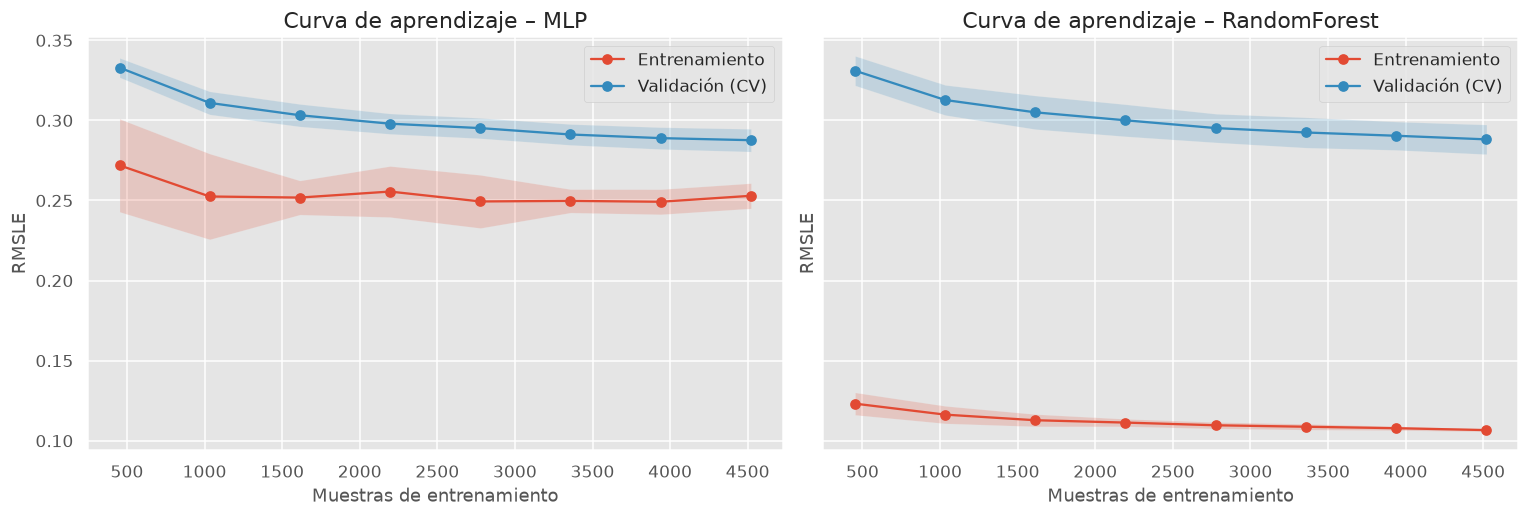

In [34]:
fig, axes = plt.subplots(1, len(PRINCIPALES), figsize=(14, 4.8), sharey=True)
for ax, nombre in zip(axes, PRINCIPALES):
    tam, tr, va = learning_curve(mejores[nombre], X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8),
                                 cv=CV_OPT, scoring=SCORING, n_jobs=N_JOBS, shuffle=True, random_state=SEED)
    (tr_m, tr_s), (va_m, va_s) = a_rmsle(tr), a_rmsle(va)
    ax.plot(tam, tr_m, "o-", label="Entrenamiento")
    ax.fill_between(tam, tr_m - tr_s, tr_m + tr_s, alpha=0.2)
    ax.plot(tam, va_m, "o-", label="Validación (CV)")
    ax.fill_between(tam, va_m - va_s, va_m + va_s, alpha=0.2)
    ax.set(title=f"Curva de aprendizaje – {nombre}", xlabel="Muestras de entrenamiento", ylabel="RMSLE")
    ax.legend()
plt.tight_layout(); plt.show()

_Comentario:_ al pasar de ≈ 500 a ≈ 4.500 muestras, el error de validación baja de ≈ 0,33 a ≈ 0,29 en ambos modelos y
sigue bajando lentamente al final: más datos ayudarían, pero con rendimientos decrecientes. La diferencia está en el
entrenamiento: la MLP se mantiene en ≈ 0,25 (brecha ≈ 0,04, poco sobreajuste) y el RF en ≈ 0,11 (brecha ≈ 0,18, casi
memoriza). Aun así, ambos llegan al mismo error de validación. Con ≈ 5.600 anuncios el tamaño del dataset no impide
entrenar la MLP.

### 9.3 Curva de pérdida de la MLP

Pérdida (MSE sobre el objetivo estandarizado) por época al entrenar la MLP optimizada con todo el conjunto de
entrenamiento. La línea vertical marca la época con menor pérdida de validación, cuyos pesos se conservan
(*early stopping*).

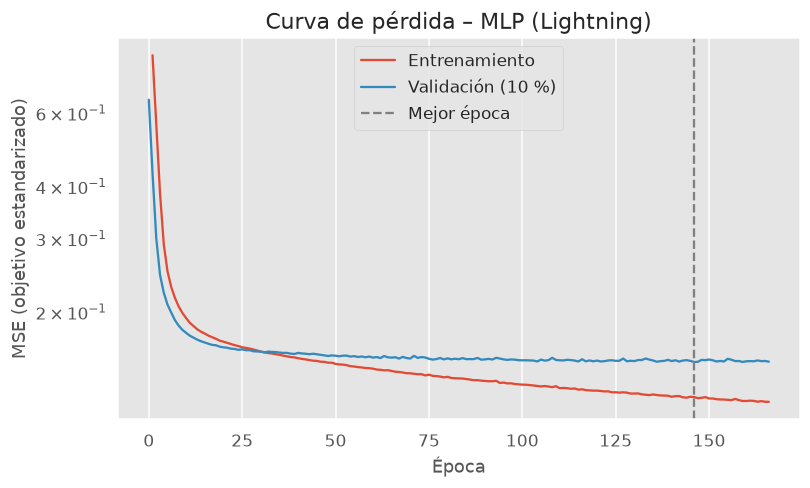

Épocas entrenadas: 167 | mejor época: 146


In [35]:
mlp_final = clone(mejores["MLP"]).fit(X_train, y_train)
hist = mlp_final.named_steps["modelo"].historial_

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(hist["epoca"], hist["train_loss"], label="Entrenamiento")
ax.plot(hist["epoca"], hist["val_loss"], label="Validación (10 %)")
ax.axvline(hist.loc[hist["val_loss"].idxmin(), "epoca"], ls="--", c="gray", label="Mejor época")
ax.set(xlabel="Época", ylabel="MSE (objetivo estandarizado)", yscale="log", title="Curva de pérdida – MLP (Lightning)")
ax.legend(); plt.show()
print(f"Épocas entrenadas: {len(hist)} | mejor época: {hist['val_loss'].idxmin()}")

_Comentario:_ la pérdida de validación baja rápido en las primeras ≈ 30 épocas y luego se estabiliza, mientras la de
entrenamiento sigue bajando lentamente. La mejor época fue la 146 y el entrenamiento se detuvo en la 167 (paciencia
de 20). La brecha final entre ambas curvas es pequeña: el *weight decay* y el *early stopping* controlan el
sobreajuste.

## 10. Comparación estadística: MLP vs. Random Forest

**Pregunta:** en este dataset tabular y relativamente pequeño, ¿una red neuronal (MLP) predice igual de bien que un
ensamble de árboles (Random Forest)? La literatura reporta que en datos tabulares de tamaño medio los ensambles de
árboles suelen superar a las redes neuronales [14]; aquí se pone a prueba con nuestros datos.

Ambos modelos optimizados se evalúan con **repeated k-fold CV** (`CV_COMP`: 10 repeticiones × 10 folds = 100
estimaciones del RMSLE por modelo) **en exactamente los mismos folds** (misma semilla): las muestras son **pareadas**.

**Hipótesis:**
- $H_0$: ambos modelos tienen el mismo desempeño (la diferencia de RMSLE por fold está centrada en 0).
- $H_1$: el desempeño es distinto.

Nivel de significancia: $\alpha = 0.05$.

**Pruebas utilizadas:**
1. **Wilcoxon de rangos con signo** [5]: no paramétrica, no asume normalidad de las diferencias; recomendada por
   Demšar [6] para comparar dos modelos.
2. **t-test pareado con corrección de Nadeau y Bengio** [4]: en *k-fold* repetido los conjuntos de entrenamiento se
   solapan, por lo que las 100 estimaciones no son independientes y el t-test clásico subestima la varianza
   (demasiados falsos positivos). La corrección infla la varianza por el factor $\left(\frac{1}{k} +
   \frac{n_{test}}{n_{train}}\right)$.

Ridge (modelo hedónico lineal) se incluye como **referencia**: muestra cuánto gana cada modelo no lineal sobre el
modelo clásico, pero no entra en la prueba de hipótesis.

In [36]:
comparar = {"MLP": mejores["MLP"], "RandomForest": mejores["RandomForest"], "Ridge (referencia)": mejores["Ridge"]}

rmsle_cv = {}
for nombre, modelo in comparar.items():
    rmsle_cv[nombre] = -cross_val_score(modelo, X_train, y_train, cv=CV_COMP, scoring=SCORING, n_jobs=N_JOBS)
    print(f"{nombre:20s} RMSLE = {rmsle_cv[nombre].mean():.4f} ± {rmsle_cv[nombre].std():.4f} "
          f"({len(rmsle_cv[nombre])} folds)")

res_cv = pd.DataFrame(rmsle_cv)
res_cv.to_csv(RESULTADOS / "rmsle_repeated_kfold.csv", index_label="fold")

MLP                  RMSLE = 0.2849 ± 0.0162 (100 folds)


RandomForest         RMSLE = 0.2860 ± 0.0165 (100 folds)


Ridge (referencia)   RMSLE = 0.3024 ± 0.0160 (100 folds)


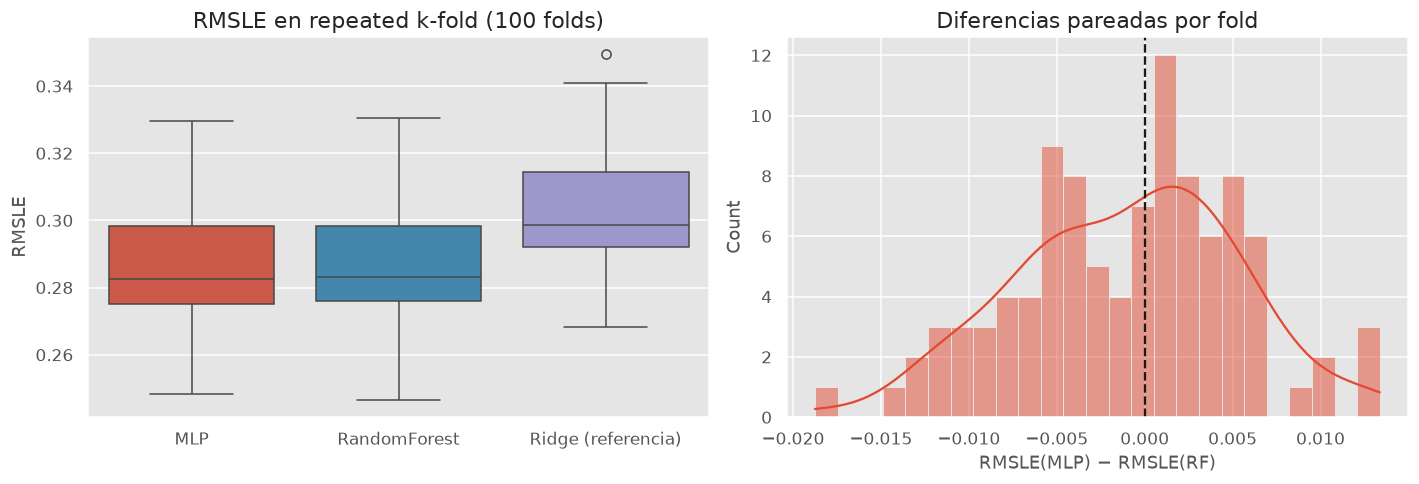

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=res_cv, ax=axes[0])
axes[0].set(ylabel="RMSLE", title=f"RMSLE en repeated k-fold ({len(res_cv)} folds)")

dif = res_cv["MLP"] - res_cv["RandomForest"]
sns.histplot(dif, bins=25, kde=True, ax=axes[1])
axes[1].axvline(0, c="k", ls="--")
axes[1].set(xlabel="RMSLE(MLP) − RMSLE(RF)", title="Diferencias pareadas por fold")
plt.tight_layout(); plt.show()

In [38]:
a, b = res_cv["MLP"].values, res_cv["RandomForest"].values
d = a - b
ALPHA = 0.05

# Normalidad de las diferencias (para decidir qué prueba es más apropiada)
sh = stats.shapiro(d)
print(f"Shapiro-Wilk sobre las diferencias: W = {sh.statistic:.3f}, p = {sh.pvalue:.4f}")

# 1) Wilcoxon de rangos con signo
w = stats.wilcoxon(a, b)
print(f"Wilcoxon: estadístico = {w.statistic:.1f}, p = {w.pvalue:.4g}")


# 2) t-test pareado corregido (Nadeau & Bengio, 2003)
def t_test_corregido(a, b, n_train, n_test):
    d = a - b
    k = len(d)
    var = d.var(ddof=1)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * var)
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return t, p


n_splits = CV_COMP.cvargs["n_splits"]
n_test_fold = len(X_train) / n_splits
n_train_fold = len(X_train) - n_test_fold
t_c, p_c = t_test_corregido(a, b, n_train_fold, n_test_fold)
t_n, p_n = stats.ttest_rel(a, b)
print(f"t-test pareado corregido: t = {t_c:.3f}, p = {p_c:.4g}")
print(f"(t-test pareado sin corregir, solo como referencia: t = {t_n:.3f}, p = {p_n:.4g})")

mejor = "MLP" if d.mean() < 0 else "RandomForest"
print(f"\nDiferencia media de RMSLE (MLP − RF): {d.mean():+.4f}; modelo con menor error: {mejor}")
for nombre, p in [("Wilcoxon", w.pvalue), ("t corregido", p_c)]:
    decision = "se RECHAZA H0" if p < ALPHA else "NO se rechaza H0"
    print(f"{nombre}: p = {p:.4g} → {decision} (α = {ALPHA})")

Shapiro-Wilk sobre las diferencias: W = 0.990, p = 0.6877
Wilcoxon: estadístico = 2120.0, p = 0.1638
t-test pareado corregido: t = -0.471, p = 0.6387
(t-test pareado sin corregir, solo como referencia: t = -1.639, p = 0.1044)

Diferencia media de RMSLE (MLP − RF): -0.0010; modelo con menor error: MLP
Wilcoxon: p = 0.1638 → NO se rechaza H0 (α = 0.05)
t corregido: p = 0.6387 → NO se rechaza H0 (α = 0.05)


_Interpretación:_ la MLP tiene un RMSLE medio apenas menor (diferencia −0,0010, ≈ 0,1 puntos porcentuales de error),
pero la diferencia **no es estadísticamente significativa**: Wilcoxon p = 0,164 y t-test corregido p = 0,639 (incluso
el t-test sin corregir da p = 0,104). Las diferencias por fold son compatibles con una normal (Shapiro-Wilk p = 0,69),
así que el t-test es aplicable. Tampoco es relevante en la práctica: con estos datos, MLP y RF son equivalentes.
Ambos superan claramente al modelo lineal (Ridge, ≈ 0,017 más de RMSLE).

> Observar que el Wilcoxon y el t-test sin corregir suelen dar p-valores mucho menores que el t-test corregido:
> ninguno de los dos considera la dependencia entre folds. Si las pruebas discrepan, la conclusión más
> conservadora (y defendible) es la del t-test corregido.

> **Nota metodológica:** los hiperparámetros se optimizaron con CV sobre el mismo conjunto de entrenamiento, por lo
> que los RMSLE de esta sección pueden ser ligeramente optimistas. Esto afecta por igual a ambos modelos, así que la
> comparación sigue siendo justa; la estimación no sesgada del error es la del conjunto de prueba (sección 11).

## 11. Evaluación final en el conjunto de prueba

Los modelos se reentrenan con todo el conjunto de entrenamiento y se evalúan una sola vez en el conjunto de prueba.
Además del RMSLE (escala del entrenamiento), las predicciones se vuelven a USD con $e^{\hat{y}}$ para reportar
errores interpretables.

In [39]:
def metricas(y_log, pred_log):
    real, pred = np.exp(y_log), np.exp(pred_log)
    return {"RMSLE": root_mean_squared_error(y_log, pred_log),
            "R² (log)": r2_score(y_log, pred_log),
            "MAE (USD)": mean_absolute_error(real, pred),
            "Mediana |error| (USD)": np.median(np.abs(real - pred)),
            "MAPE (%)": 100 * mean_absolute_percentage_error(real, pred),
            "RMSE (USD)": root_mean_squared_error(real, pred)}


predicciones, tabla = {}, {}
for nombre, modelo in comparar.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)
    tabla[nombre] = metricas(y_test, predicciones[nombre])

pd.DataFrame(tabla).T.to_csv(RESULTADOS / "metricas_test.csv")
pd.DataFrame(tabla).T.style.format({"RMSLE": "{:.4f}", "R² (log)": "{:.3f}", "MAE (USD)": "{:,.0f}",
                                    "Mediana |error| (USD)": "{:,.0f}", "MAPE (%)": "{:.1f}",
                                    "RMSE (USD)": "{:,.0f}"})

,RMSLE,R² (log),MAE (USD),Mediana |error| (USD),MAPE (%),RMSE (USD)
MLP,0.2949,0.818,"49,673","21,530",21.1,"142,130"
RandomForest,0.2943,0.819,"48,646","19,637",20.7,"141,059"
Ridge (referencia),0.3151,0.792,"53,893","22,241",23.2,"145,864"


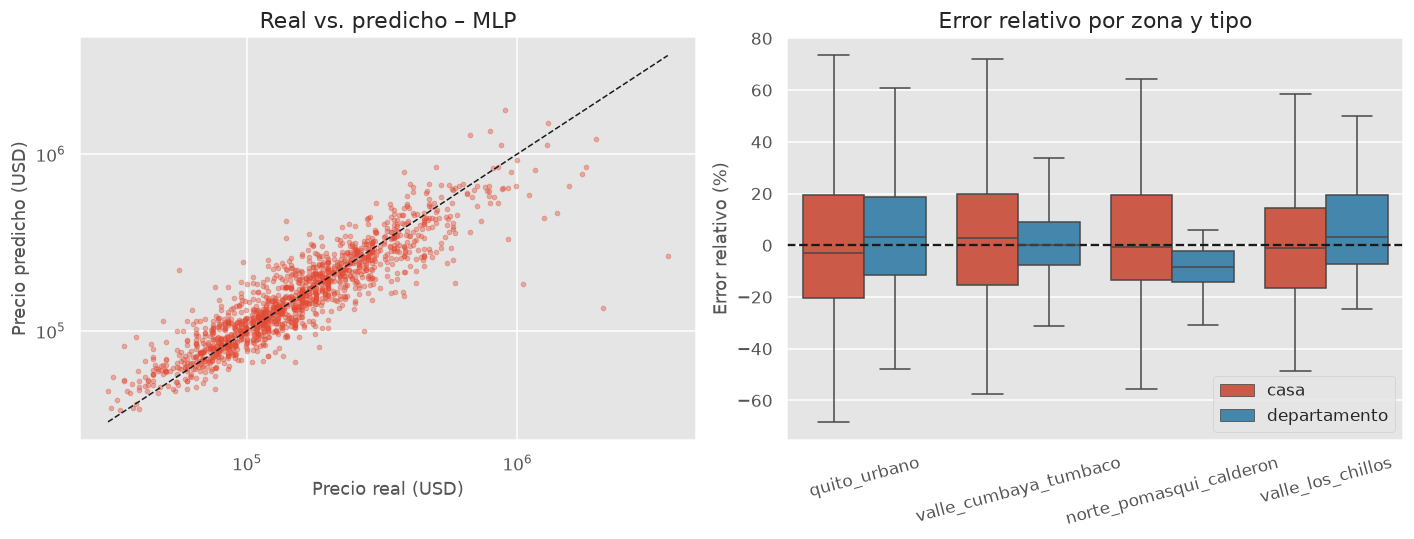

In [40]:
final = mejor   # modelo con menor error en la comparación (sección 10)
real, pred = np.exp(y_test), np.exp(predicciones[final])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(real, pred, s=10, alpha=0.4)
lim = [min(real.min(), pred.min()), max(real.max(), pred.max())]
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set(xscale="log", yscale="log", xlabel="Precio real (USD)", ylabel="Precio predicho (USD)",
            title=f"Real vs. predicho – {final}")

err_rel = (pred - real) / real * 100
sns.boxplot(x=X_test["zona"].values, y=err_rel.values, hue=X_test["tipo"].values, showfliers=False, ax=axes[1])
axes[1].axhline(0, c="k", ls="--")
axes[1].set(xlabel="", ylabel="Error relativo (%)", title="Error relativo por zona y tipo")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

In [41]:
# Características que sobrevivieron al filtro en el modelo final
pipe_final = comparar[final]
nombres = pipe_final.named_steps["preprocesamiento"].get_feature_names_out()
nombres = nombres[pipe_final.named_steps["varianza"].get_support()]
mask = pipe_final.named_steps["seleccion"].get_support()
print(f"Características seleccionadas: {mask.sum()} de {len(mask)}")
print("Descartadas por el filtro:", list(nombres[~mask]))

Características seleccionadas: 111 de 124
Descartadas por el filtro: ['amoblado', 'sector_Andalucía', 'sector_Bellavista', 'sector_La Armenia', 'sector_La Pampa', 'sector_La Pradera', 'sector_Pifo', 'sector_Rumiñahui', 'sector_San Juan', 'sector_San Rafael', 'sector_Santa Lucia Alta', 'sector_Solca', 'sector_Viña Alta']


_Comentario:_ en el conjunto de prueba, RF (RMSLE 0,294) y MLP (0,295) quedan prácticamente empatados, coherentes
con la sección 10, y ambos superan a Ridge (0,315). El error es algo mayor que en CV (≈ 0,285): el pequeño optimismo
esperable al ajustar hiperparámetros con CV. El error mediano (≈ USD 20.000) es mucho menor que el MAE (≈ USD 49.000)
y el RMSE (≈ USD 141.000): unos pocos errores grandes en propiedades caras dominan las métricas en dólares. En el
gráfico real vs. predicho las predicciones se comprimen hacia el centro: las propiedades más caras se subestiman.
Por zona, las casas tienen errores más dispersos que los departamentos; los departamentos de Pomasqui–Calderón
tienden a subestimarse (pocos anuncios en esa combinación).

## 12. Visualización del espacio de características con t-SNE

Se proyecta a 2 dimensiones con t-SNE [3] el espacio de características **después del preprocesamiento y la
selección** del modelo final (lo que realmente “ve” el modelo). Como el problema es de regresión, cada punto se colorea
por su **precio** (escala log); en el segundo panel, por zona.

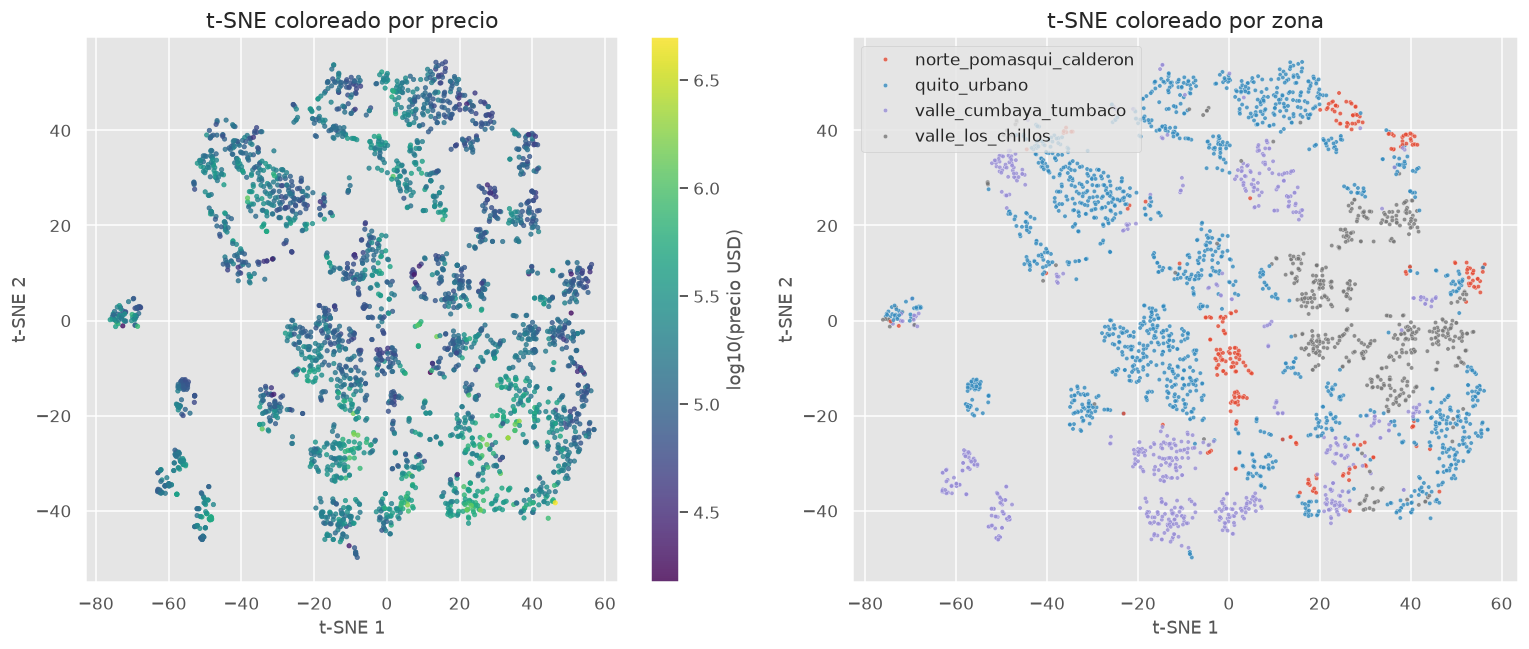

In [42]:
N_TSNE = 3000
idx = rng.choice(len(X_train), size=min(N_TSNE, len(X_train)), replace=False)
X_sub, y_sub = X_train.iloc[idx], y_train.iloc[idx]

Z = pipe_final[:-1].transform(X_sub)   # preprocesamiento + varianza + selección (sin el modelo)
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc = axes[0].scatter(emb[:, 0], emb[:, 1], c=y_sub / np.log(10), cmap="viridis", s=8, alpha=0.8)
plt.colorbar(sc, ax=axes[0], label="log10(precio USD)")
axes[0].set_title("t-SNE coloreado por precio")
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=X_sub["zona"].values, s=8, alpha=0.8, ax=axes[1])
axes[1].set_title("t-SNE coloreado por zona")
for ax in axes:
    ax.set(xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.show()

_Comentario:_ se ven grupos bien definidos por zona: Quito urbano, Cumbayá–Tumbaco, Los Chillos y Pomasqui–Calderón
ocupan regiones distintas, en parte porque zona, sector y coordenadas son entradas del modelo. El precio, en cambio,
varía dentro de cada grupo, sin un gradiente claro entre grupos: dentro de una misma zona lo determinan sobre todo
el área y el tipo. En t-SNE solo la estructura local es interpretable: las distancias entre grupos lejanos y
el tamaño de los grupos no tienen significado.

## 13. Conclusiones

1. **Desempeño.** En el conjunto de prueba (1.413 anuncios no usados en ninguna etapa de ajuste), el Random Forest
   obtuvo RMSLE = 0,294 (MAPE 20,7 %, error mediano USD 19.600) y la MLP RMSLE = 0,295 (MAPE 21,1 %, error mediano
   USD 21.500). Ambos superan al modelo hedónico lineal (Ridge: RMSLE 0,315, MAPE 23,2 %) en unos 2 puntos de MAPE. 
   Las no linealidades e interacciones aportan, pero un modelo log-log lineal ya captura la mayor parte de la
   estructura del precio.
2. **Comparación estadística.** Con *repeated k-fold* 10×10, la diferencia media de RMSLE entre MLP y RF fue
   −0,0010 (≈ 0,1 puntos porcentuales de error). Ni el Wilcoxon (p = 0,164) ni el t-test corregido de
   Nadeau–Bengio (p = 0,639) la consideran significativa con α = 0,05. Tampoco es relevante en la práctica: con
   estos datos ambas técnicas son equivalentes, y la elección puede basarse en otros criterios (el RF es más simple
   de entrenar; la MLP generaliza con menos brecha entre entrenamiento y validación).
3. **Variables influyentes.** El área construida es por lejos la variable más asociada al precio (estadístico F del
   filtro), seguida de baños, área de terreno, la zona Cumbayá–Tumbaco y parqueaderos. La ubicación pesa mucho: el
   sector explica el 43 % de la varianza de log(precio/m²) y sectores vecinos tienen precios parecidos (r = 0,77).
   El filtro de selección conservó el 90 % de las características en la MLP y el 100 % en el RF: con pocas
   variables irrelevantes, la selección aporta poco.
4. **Quito vs. valles.** El valle de Cumbayá–Tumbaco es la zona más cara (mediana ≈ USD 1.190/m² frente a ≈ 810 en
   Quito urbano), mientras Los Chillos y Pomasqui–Calderón son más baratos. En los errores, las casas tienen mayor
   dispersión que los departamentos en todas las zonas, y el modelo subestima las propiedades más caras.
5. **Curvas de aprendizaje.** El error de validación de ambos modelos sigue bajando lentamente con el 100 % de los
   datos: más anuncios ayudarían, pero con rendimientos decrecientes. El RF casi memoriza el conjunto de
   entrenamiento (RMSLE de entrenamiento ≈ 0,11 vs. ≈ 0,29 en validación); la MLP tiene una brecha mucho menor
   (≈ 0,25 vs. ≈ 0,29), controlada principalmente por el *weight decay*, el hiperparámetro más importante según
   Optuna.
6. **Limitaciones.** La principal limitación es la muestra: los anuncios en línea son un
   subconjunto no aleatorio del mercado de Quito (ver el aviso en la introducción), así que los resultados describen
   ese subconjunto y no el mercado completo. Las propiedades de menor valor económico están subrepresentadas en el
   dataset, porque rara vez se anuncian en línea y no están disponibles para _web scraping_. En particular, la suavidad espacial del precio vale para los anuncios
   en línea, no necesariamente para la ciudad. Además, los precios son de oferta, no de cierre; muchas coordenadas son aproximadas (centroides de barrio); hay faltantes altos en antigüedad, estado y alícuota; y parte de los datos de
   arriendayvende es de 2021–2022. Por último, las reglas de limpieza se definieron en un EDA hecho antes de la
   partición.
   Este trabajo se realiza para demostrar la metodología de un pipeline completo de desarrollo y comparación de modelos de machine learning y no pretende ser un modelo para predecir con exactitud el precio de un bien inmueble.

## 14. Transparencia sobre el uso de IA

Este proyecto se desarrolló con la asistencia de **Claude Opus 5.5** (Anthropic) [17], usado a través de Claude Code,
una herramienta que puede leer y escribir archivos y ejecutar comandos. Para que el alcance de esa asistencia quede
claro:

**Lo que hizo Claude**
- Escribió prácticamente todo el código: los *scrapers* y el script de construcción del dataset (`scraper/`), el
  notebook completo (EDA, pipeline, clases de PyTorch Lightning, optimización, pruebas estadísticas, gráficos) y el
  `Dockerfile`.
- Ejecutó el *scraping*, las corridas del notebook en la infraestructura de la universidad y las revisiones de los
  resultados. La extracción de datos de los sitios de constructoras la hicieron agentes de Claude (modelo Haiku) que
  leyeron las páginas de los proyectos.
- Propuso la mayoría de los detalles técnicos: reglas de limpieza, variables derivadas, rangos de búsqueda de
  hiperparámetros, esquema de validación y pruebas estadísticas.
- Redactó un primer borrador de los comentarios de interpretación y de las conclusiones a partir de los resultados
  obtenidos, así como la documentación (README) y los textos de los avisos a partir de las indicaciones del autor.

**Lo que decidió el autor**
- El alcance del problema y los requisitos del dataset; qué fuentes usar y cuáles descartar (sin eludir protecciones
  anti-bots ni guardar datos personales de agentes o vendedores).
- Las reglas de dominio: un precio "desde" corresponde a la unidad más pequeña; `quito_urbano` es la ciudad de Quito
  y no un sector; `fuente` sirve solo para trazabilidad.
- La revisión manual de las coordenadas de los proyectos nuevos y de las correcciones de sector.
- Las decisiones de modelado: entrenar sobre log(precio) en el preprocesamiento común; comparar **MLP vs. Random
  Forest** (técnicas vistas en clase) con Ridge como referencia; implementar la MLP con PyTorch Lightning; ejecutar en
  un contenedor Docker en los servidores de la universidad.
- El aviso sobre el alcance de los datos: que los anuncios en línea son un subconjunto no aleatorio del mercado y
  que, en el norte de Quito, zonas ricas y pobres colindan (conocimiento del autor sobre la ciudad).
- La aprobación de las propuestas técnicas de Claude, en algunos casos tras pedir explicaciones o alternativas.
- La revisión de los textos de interpretación y conclusiones: el autor editó las conclusiones y corrigió
  interpretaciones del borrador (p. ej. que los faltantes informativos de la sección 4.11 son asociaciones a través
  de la fuente y no efectos causales); el resto de los comentarios son borradores de Claude revisados por el autor.

No se incluye la lista de *prompts*: el trabajo se hizo en conversaciones largas e iterativas (decenas de
intercambios), que no se pueden resumir en unos pocos *prompts* sin distorsionarlas. Los registros completos de las
sesiones están disponibles a pedido.

## 15. Referencias

[1] F. Pedregosa *et al.*, “Scikit-learn: Machine learning in Python,” *J. Mach. Learn. Res.*, vol. 12,
pp. 2825–2830, 2011.

[2] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, “Optuna: A next-generation hyperparameter optimization
framework,” in *Proc. 25th ACM SIGKDD Int. Conf. Knowl. Discov. Data Min.*, 2019, pp. 2623–2631.

[3] L. van der Maaten and G. Hinton, “Visualizing data using t-SNE,” *J. Mach. Learn. Res.*, vol. 9,
pp. 2579–2605, 2008.

[4] C. Nadeau and Y. Bengio, “Inference for the generalization error,” *Mach. Learn.*, vol. 52, no. 3,
pp. 239–281, 2003.

[5] F. Wilcoxon, “Individual comparisons by ranking methods,” *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, 1945.

[6] J. Demšar, “Statistical comparisons of classifiers over multiple data sets,” *J. Mach. Learn. Res.*, vol. 7,
pp. 1–30, 2006.

[7] D. E. Rumelhart, G. E. Hinton, and R. J. Williams, “Learning representations by back-propagating errors,”
*Nature*, vol. 323, no. 6088, pp. 533–536, 1986.

[8] L. Breiman, “Random forests,” *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, 2001.

[9] D. P. Kingma and J. Ba, “Adam: A method for stochastic optimization,” in *Proc. 3rd Int. Conf. Learn.
Represent. (ICLR)*, 2015.

[10] Dataset propio construido a partir de: icasas.ec, “Casas y departamentos en venta en Quito”; RE/MAX Ecuador,
“Comprar propiedades”; Arrienda y Vende, “Casas de venta en Quito”; Trivo, “Casas en venta en Quito”, 2026.
Accedido: 11–12 nov. 2026. Referencias completas en `data/README.md`.

[11] scikit-learn developers, “Plot validation and learning curves,” scikit-learn documentation. [Online].
Available: https://scikit-learn.org/stable/modules/learning_curve.html

[12] S. Rosen, “Hedonic prices and implicit markets: Product differentiation in pure competition,” *J. Polit. Econ.*,
vol. 82, no. 1, pp. 34–55, 1974.

[13] A. E. Hoerl and R. W. Kennard, “Ridge regression: Biased estimation for nonorthogonal problems,”
*Technometrics*, vol. 12, no. 1, pp. 55–67, 1970.

[14] L. Grinsztajn, E. Oyallon, and G. Varoquaux, “Why do tree-based models still outperform deep learning on
typical tabular data?,” in *Adv. Neural Inf. Process. Syst. 35*, 2022, pp. 507–520.

[15] W. Falcon and The PyTorch Lightning team, “PyTorch Lightning,” 2019. [Online]. Available:
https://github.com/Lightning-AI/pytorch-lightning, doi: 10.5281/zenodo.3828935.

[16] A. Paszke *et al.*, “PyTorch: An imperative style, high-performance deep learning library,” in *Adv. Neural
Inf. Process. Syst. 32*, 2019, pp. 8024–8035.

[17] Anthropic, “Claude Opus 5.5,” modelo de lenguaje, 2026. Usado mediante Claude Code. [Online]. Available:
https://www.anthropic.com